In [1]:
import pandas as pd
import glob
import os

print("Scanning folder for marine files...")

# 1. Automatically find all files that start with "marine" and end with ".csv"
file_list = glob.glob("marine*.csv")
all_data = []

for file in file_list:
    try:
        # Try reading as standard CSV
        temp_df = pd.read_csv(file, on_bad_lines='skip')
    except:
        try:
            # If that fails (because it's secretly an Excel file), try reading as Excel
            temp_df = pd.read_excel(file)
        except Exception as e:
            print(f"❌ Could not read {file}: {e}")
            continue

    # 2. Extract the year (finds 4-digit number in the filename)
    import re
    year_match = re.search(r'\d{4}', file)
    if year_match:
        temp_df['Year'] = int(year_match.group())
    else:
        temp_df['Year'] = 0 # Fallback if no year found

    all_data.append(temp_df)
    print(f"✅ Loaded {file} (Year: {temp_df['Year'][0]})")

# 3. Combine and Save
if all_data:
    master_df = pd.concat(all_data, ignore_index=True)
    master_df.to_csv("master_sea_data.csv", index=False)
    print("\n🎉 SUCCESS! Created master_sea_data.csv")
    print(f"Total rows combined: {len(master_df)}")
    print("Columns found:", master_df.columns.tolist())
else:
    print("\n❌ No marine files found. Check the folder.")

Scanning folder for marine files...
✅ Loaded marine  2009.csv (Year: 2009)
✅ Loaded marine 2007 .csv (Year: 2007)
✅ Loaded marine 2008.csv (Year: 2008)
✅ Loaded marine 2010.csv (Year: 2010)
✅ Loaded marine 2011.csv (Year: 2011)
✅ Loaded marine 2012.csv (Year: 2012)

🎉 SUCCESS! Created master_sea_data.csv
Total rows combined: 371
Columns found: ['Sl. No.', 'Species', 'Andhra Pradesh ', ' Orissa', 'Tamil Nadu', 'West Bengal', 'Andaman & Nicobar ', 'Pondicherry', 'East Total', ' Gujarat', 'Karnataka', ' Kerala', ' Maharashtra', ' Goa', ' Lakshadweep', ' Daman & Diu', 'West Total', 'Total for India', 'Year', 'SL. No ', 'Andhra Pradesh', 'Orissa', 'Andaman & Nicobar', ' Karnataka', 'Maharashtra', 'Goa', 'Lakshadweep', 'Karntaka']



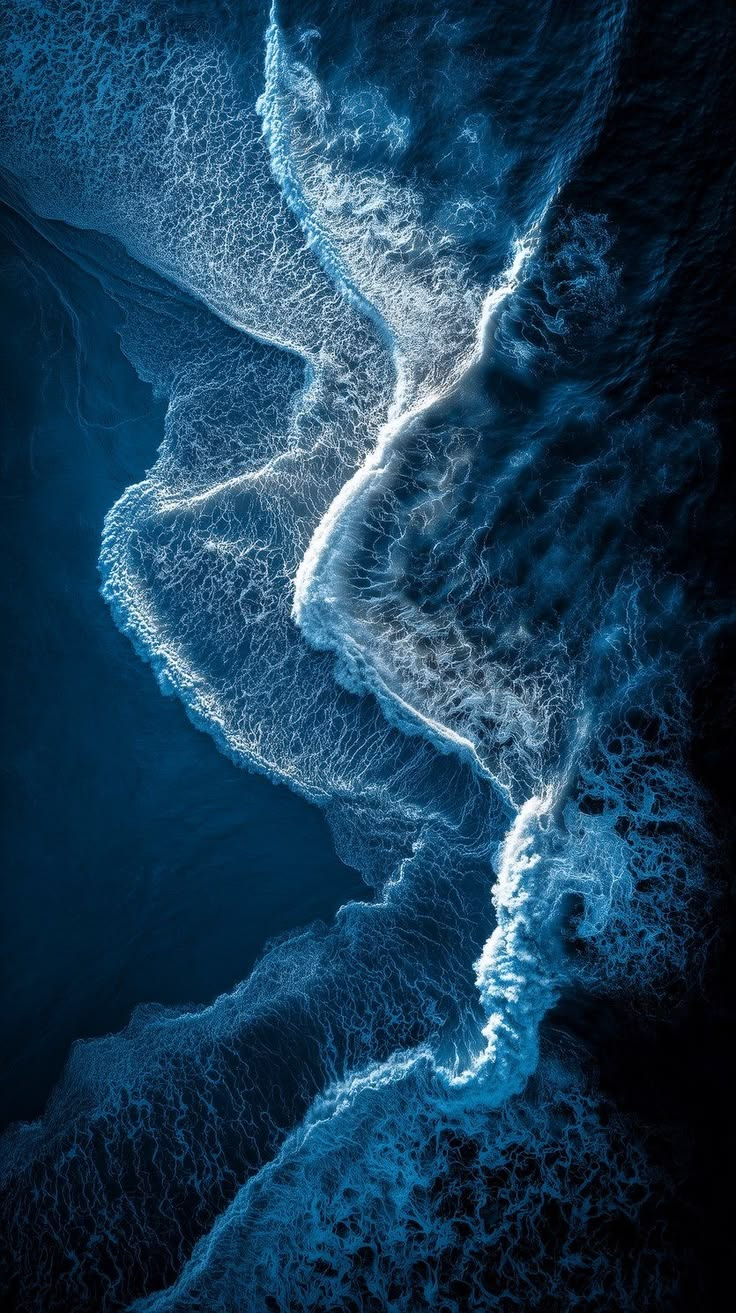

In [2]:
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
from IPython.display import display, HTML, clear_output
import base64
import os
import json

# ==========================================
# 1. LOAD BACKGROUND IMAGE
# ==========================================
image_path = "sea bg.jpg"
if os.path.exists(image_path):
    with open(image_path, "rb") as f:
        img_data = f.read()
    bg_base64 = base64.b64encode(img_data).decode()
else:
    bg_base64 = ""
    print("⚠️ 'sea bg.jpg' not found.")

# ==========================================
# 2. LOAD DATA (SAFELY)
# ==========================================
try:
    # Try loading the aggregated file first
    df = pd.read_csv("aggregated_marine_data.csv")
except:
    # Fallback to master file if aggregated doesn't exist yet
    df = pd.read_csv("master_sea_data.csv")

# Dynamically find the correct column names
year_col = next((col for col in df.columns if 'year' in str(col).lower()), df.columns[0])
fish_col = next((col for col in df.columns if 'fish' in str(col).lower() or 'specie' in str(col).lower()), df.columns[1])
state_col = next((col for col in df.columns if 'state' in str(col).lower() or 'region' in str(col).lower()), df.columns[2])

# Clean up the data
df[year_col] = pd.to_numeric(df[year_col], errors='coerce').fillna(0).astype(int)

# Get unique lists for dropdowns
all_fish = sorted(df[fish_col].dropna().unique().tolist())
all_states = sorted(df[state_col].dropna().unique().tolist())

# Create HTML option strings
fish_options = "".join([f"<option value='{fish}'>{fish}</option>" for fish in all_fish])
state_options = "".join([f"<option value='{state}'>{state}</option>" for state in all_states])

# ==========================================
# 3. THE ARCADE HTML/CSS INTERFACE
# ==========================================
arcade_html = f"""
<style>
@import url('https://fonts.googleapis.com/css2?family=Press+Start+2P&display=swap');

/* Main Background */
.arcade-container {{
    background-image: url('data:image/jpeg;base64,{bg_base64}');
    background-size: cover;
    background-position: center;
    background-attachment: fixed;
    padding: 50px;
    border-radius: 20px;
    font-family: 'Press Start 2P', cursive;
    min-height: 600px;
    display: flex;
    flex-direction: column;
    align-items: center;
    box-shadow: inset 0 0 100px rgba(0,0,0,0.8);
}}

/* Main Title */
.arcade-title {{
    font-size: 2.5rem;
    color: #38bdf8; /* Cyan */
    text-shadow: 4px 4px 0px #000, 0 0 20px rgba(56, 189, 248, 0.8);
    text-align: center;
    margin-bottom: 20px;
    line-height: 1.5;
}}

/* Subtitle */
.arcade-subtitle {{
    font-size: 0.8rem;
    color: #f59e0b; /* Amber */
    text-shadow: 2px 2px 0px #000;
    margin-top: -10px;
    margin-bottom: 30px;
}}

/* Glass Menu Box */
.arcade-glass {{
    background: rgba(15, 23, 42, 0.85);
    backdrop-filter: blur(15px);
    border: 3px solid #38bdf8;
    border-radius: 15px;
    padding: 40px;
    box-shadow: 0 10px 40px rgba(0, 0, 0, 0.7), inset 0 0 20px rgba(56, 189, 248, 0.3);
    width: 80%;
    max-width: 800px;
    text-align: center;
    position: relative;
}}

/* The Start Button */
.start-btn {{
    font-family: 'Press Start 2P', cursive;
    font-size: 1.2rem;
    background-color: #f59e0b; /* Amber */
    color: #000;
    padding: 20px 40px;
    border: 4px solid #fff;
    border-radius: 10px;
    cursor: pointer;
    margin-top: 20px;
    box-shadow: 0 8px 0px #b45309;
    transition: all 0.1s;
    animation: pulse 1.5s infinite;
}}

.start-btn:active {{
    transform: translateY(8px);
    box-shadow: 0 0px 0px #b45309;
}}

@keyframes pulse {{
    0% {{ transform: scale(1); }}
    50% {{ transform: scale(1.05); }}
    100% {{ transform: scale(1); }}
}}

/* The Hidden Filter Panel (Game Zone) */
.game-zone {{
    display: none; /* Hidden by default */
    margin-top: 30px;
    background: rgba(0, 0, 0, 0.6);
    border: 2px dashed #38bdf8;
    border-radius: 10px;
    padding: 20px;
    text-align: left;
    color: white;
}}

/* Styled Select Dropdowns */
select {{
    appearance: none;
    background-color: #1e293b;
    color: #38bdf8;
    border: 2px solid #38bdf8;
    border-radius: 8px;
    padding: 12px;
    font-family: 'Press Start 2P', cursive;
    font-size: 0.8rem;
    width: 100%;
    margin-bottom: 15px;
    cursor: pointer;
    outline: none;
}}

select:hover {{
    box-shadow: 0 0 15px rgba(56, 189, 248, 0.5);
}}

label {{
    font-size: 0.8rem;
    color: #f59e0b;
    display: block;
    margin-bottom: 8px;
}}
</style>

<div class="arcade-container">
    <div class="arcade-title">MARINE QUEST</div>
    <div class="arcade-subtitle">CATCH & CLIMATE 2007-2012</div>
    
    <div class="arcade-glass">
        <p style="color: white; font-size: 0.8rem; line-height: 2;">Welcome, Player 1.<br>Insert data to begin your exploration of the Indian Ocean.</p>
        
        <button class="start-btn" onclick="startGame()">PRESS START</button>
        
        <div class="game-zone" id="gameZone">
            <label>🐟 SELECT FISH SPECIES:</label>
            <select id="fishSelect">
                <option value="All Fish">-- ALL SPECIES --</option>
                {fish_options}
            </select>

            <label>📍 SELECT REGION:</label>
            <select id="stateSelect">
                <option value="All States">-- ALL STATES --</option>
                {state_options}
            </select>
            
            <p style="font-size: 0.6rem; color: #10b981; text-align: center; margin-top: 10px;">>> SELECTIONS LOADED <<</p>
        </div>
    </div>
</div>

<script>
function startGame() {{
    var zone = document.getElementById("gameZone");
    if (zone.style.display === "block") {{
        zone.style.display = "none";
    }} else {{
        zone.style.display = "block";
    }}
}}
</script>
"""

# Display the Arcade UI
display(HTML(arcade_html))


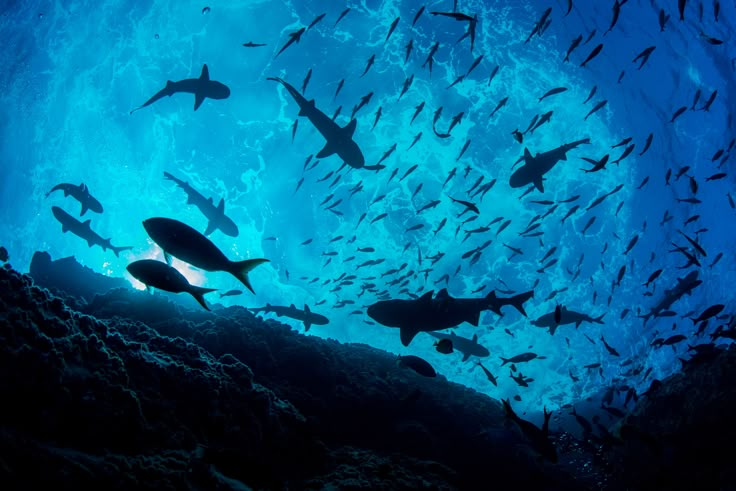

In [3]:
from IPython.display import display, HTML
import base64
import os

# ==========================================
# 1. LOAD UNDERSEA IMAGE
# ==========================================
image_path = "undersea.jpg"
if os.path.exists(image_path):
    with open(image_path, "rb") as f:
        img_data = f.read()
    bg_base64 = base64.b64encode(img_data).decode()
else:
    bg_base64 = ""
    print("⚠️ 'undersea.jpg' not found. Please ensure it's in the folder.")

# ==========================================
# 2. THE PORTAL UI
# ==========================================
display(HTML(f"""
<style>
@import url('https://fonts.googleapis.com/css2?family=Press+Start+2P&display=swap');

/* Full Screen Undersea Background */
.sea-portal {{
    background-image: url('data:image/jpeg;base64,{bg_base64}');
    background-size: cover;
    background-position: center;
    background-attachment: fixed;
    height: 70vh;
    min-height: 500px;
    border-radius: 20px;
    display: flex;
    flex-direction: column;
    justify-content: center;
    align-items: center;
    box-shadow: inset 0 0 100px rgba(0,0,0,0.9);
    position: relative;
    overflow: hidden;
}}

/* The Text */
.ready-text {{
    font-family: 'Press Start 2P', cursive;
    font-size: 4rem;
    color: #ffffff;
    text-shadow: 4px 4px 0px #000, 0 0 30px rgba(56, 189, 248, 0.8);
    margin-bottom: 40px;
    text-align: center;
    animation: floatText 3s ease-in-out infinite;
    z-index: 2;
}}

@keyframes floatText {{
    0% {{ transform: translateY(0px); }}
    50% {{ transform: translateY(-15px); }}
    100% {{ transform: translateY(0px); }}
}}

/* The Start Button */
.dive-btn {{
    font-family: 'Press Start 2P', cursive;
    font-size: 1.5rem;
    background-color: #f59e0b; /* Amber */
    color: #000;
    padding: 25px 50px;
    border: 4px solid #fff;
    border-radius: 15px;
    cursor: pointer;
    box-shadow: 0 10px 0px #b45309, 0 0 40px rgba(245, 158, 11, 0.6);
    transition: all 0.1s;
    z-index: 2;
    letter-spacing: 2px;
}}

.dive-btn:active {{
    transform: translateY(10px);
    box-shadow: 0 0px 0px #b45309;
}}

.dive-btn:hover {{
    background-color: #fbbf24;
    transform: scale(1.05);
}}

/* Bubbles Animation (Optional aesthetic touch) */
.bubble {{
    position: absolute;
    background: rgba(255, 255, 255, 0.2);
    border-radius: 50%;
    bottom: -50px;
    animation: rise 4s infinite ease-in;
}}

@keyframes rise {{
    0% {{ transform: translateY(0); opacity: 1; }}
    100% {{ transform: translateY(-600px); opacity: 0; }}
}}
</style>

<div class="sea-portal">
    <!-- Decorative Bubbles -->
    <div class="bubble" style="left: 20%; width: 20px; height: 20px; animation-delay: 0s;"></div>
    <div class="bubble" style="left: 50%; width: 40px; height: 40px; animation-delay: 1s;"></div>
    <div class="bubble" style="left: 80%; width: 15px; height: 15px; animation-delay: 2s;"></div>
    
    <div class="ready-text">READY TO SEA?</div>
    <button class="dive-btn" onclick="this.innerHTML='DIVING IN...'; this.style.backgroundColor='#10b981';">START</button>
</div>
"""))

In [4]:
import pandas as pd
import glob
import os
import re

print("Scanning folder for marine files...")
file_list = glob.glob("marine*.csv")
all_data = []

for file in file_list:
    try:
        temp_df = pd.read_csv(file, on_bad_lines='skip')
    except:
        try:
            temp_df = pd.read_excel(file)
        except Exception as e:
            print(f"❌ Could not read {file}: {e}")
            continue

    # Add Year
    year_match = re.search(r'\d{4}', file)
    if year_match:
        temp_df['Year'] = int(year_match.group())

    # --- THE FIX: AUTO-DETECT AND RENAME COLUMNS ---
    # 1. Find the column with the catch numbers
    catch_cols = [c for c in temp_df.columns if 'catch' in str(c).lower() or 'volume' in str(c).lower() or 'value' in str(c).lower() or 'qty' in str(c).lower()]
    if catch_cols:
        temp_df.rename(columns={catch_cols[0]: 'Catch_Volume'}, inplace=True)
    else:
        # If we can't find it by name, just grab the first number column that isn't Year
        num_cols = [c for c in temp_df.select_dtypes(include=['number']).columns if c != 'Year']
        if num_cols:
            temp_df.rename(columns={num_cols[0]: 'Catch_Volume'}, inplace=True)

    # 2. Find the Fish column
    fish_cols = [c for c in temp_df.columns if 'fish' in str(c).lower() or 'specie' in str(c).lower()]
    if fish_cols:
        temp_df.rename(columns={fish_cols[0]: 'Fish_Name'}, inplace=True)

    # 3. Find the State column
    state_cols = [c for c in temp_df.columns if 'state' in str(c).lower() or 'region' in str(c).lower()]
    if state_cols:
        temp_df.rename(columns={state_cols[0]: 'State'}, inplace=True)

    all_data.append(temp_df)
    print(f"✅ Loaded {file}")

if all_data:
    master_df = pd.concat(all_data, ignore_index=True)
    master_df.to_csv("master_sea_data.csv", index=False)
    print("\n🎉 SUCCESS! Created master_sea_data.csv")
    print(f"Total rows: {len(master_df)}")
    print("Columns now available:", master_df.columns.tolist())
else:
    print("\n❌ No marine files found.")

Scanning folder for marine files...
✅ Loaded marine  2009.csv
✅ Loaded marine 2007 .csv
✅ Loaded marine 2008.csv
✅ Loaded marine 2010.csv
✅ Loaded marine 2011.csv
✅ Loaded marine 2012.csv

🎉 SUCCESS! Created master_sea_data.csv
Total rows: 371
Columns now available: ['Sl. No.', 'Fish_Name', 'Catch_Volume', ' Orissa', 'Tamil Nadu', 'West Bengal', 'Andaman & Nicobar ', 'Pondicherry', 'East Total', ' Gujarat', 'Karnataka', ' Kerala', ' Maharashtra', ' Goa', ' Lakshadweep', ' Daman & Diu', 'West Total', 'Total for India', 'Year', 'Andhra Pradesh ', 'Orissa', 'Andaman & Nicobar', ' Karnataka', 'Maharashtra', 'Goa', 'Lakshadweep', 'Karntaka']



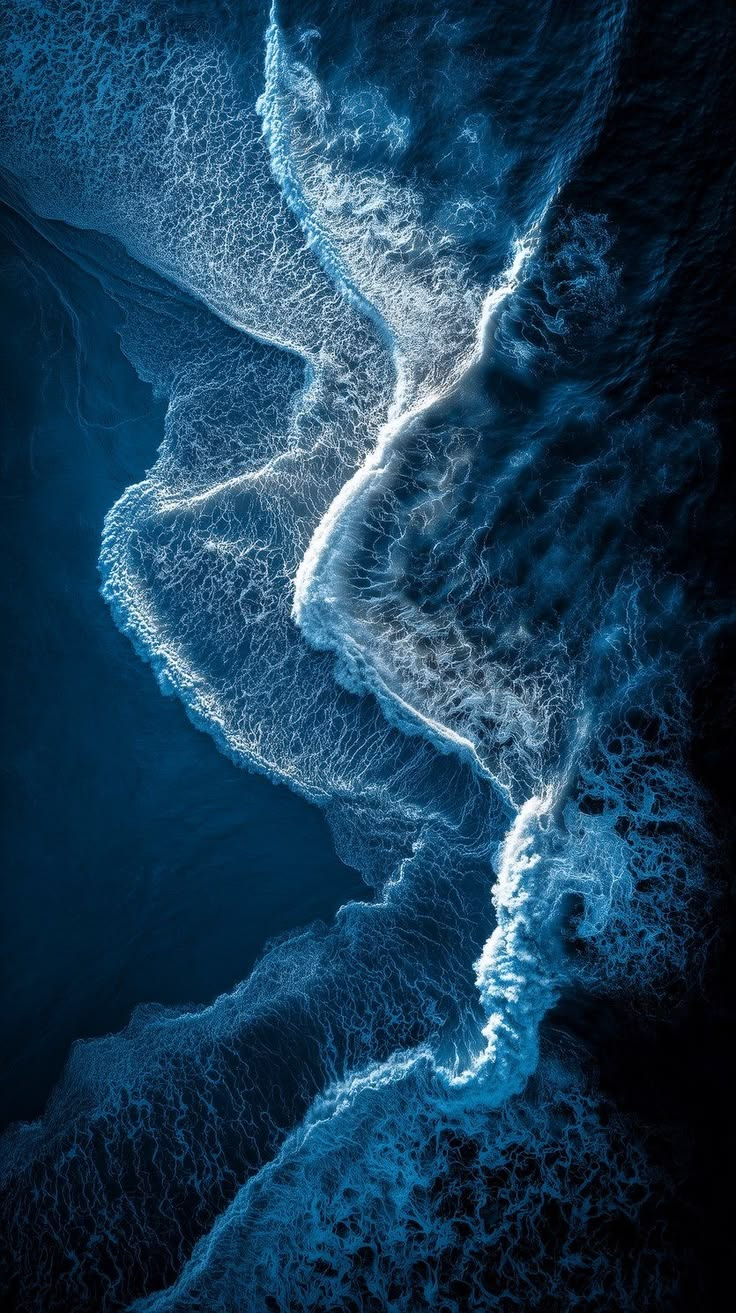

In [5]:
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
from IPython.display import display, HTML
import base64
import os
import glob
import re

# ==========================================
# 1. LOAD BACKGROUND & DATA
# ==========================================
image_path = "sea bg.jpg"
bg_base64 = ""
if os.path.exists(image_path):
    with open(image_path, "rb") as f:
        bg_base64 = base64.b64encode(f.read()).decode()

# Build master file if missing
if not os.path.exists("master_sea_data.csv"):
    file_list = glob.glob("marine*.csv")
    all_data = []
    for file in file_list:
        try:
            temp_df = pd.read_csv(file, on_bad_lines='skip')
        except:
            temp_df = pd.read_excel(file)
        year_match = re.search(r'\d{4}', file)
        if year_match:
            temp_df['Year'] = int(year_match.group())
        all_data.append(temp_df)
    df = pd.concat(all_data, ignore_index=True)
    df.to_csv("master_sea_data.csv", index=False)
else:
    df = pd.read_csv("master_sea_data.csv")

# Auto-detect columns safely
year_col = next((c for c in df.columns if 'year' in str(c).lower()), df.columns[0])
fish_col = next((c for c in df.columns if 'fish' in str(c).lower() or 'specie' in str(c).lower()), df.columns[1])
state_col = next((c for c in df.columns if 'state' in str(c).lower() or 'region' in str(c).lower()), df.columns[2])
catch_col = next((c for c in df.columns if 'catch' in str(c).lower() or 'volume' in str(c).lower() or 'value' in str(c).lower()), None)
if not catch_col:
    num_cols = [c for c in df.select_dtypes(include=['number']).columns if c != year_col]
    catch_col = num_cols[0] if num_cols else df.columns[3]

# Standardize and clean
df['Year'] = pd.to_numeric(df[year_col], errors='coerce').fillna(0).astype(int)
df['Fish_Name'] = df[fish_col].fillna('Unknown Fish')
df['State'] = df[state_col].fillna('Unknown Coast')
df['Catch_Volume'] = pd.to_numeric(df[catch_col], errors='coerce').fillna(0)
df['Catch_Lakhs'] = df['Catch_Volume'] / 100000

all_fish = sorted(df['Fish_Name'].unique().tolist())

# ==========================================
# 2. BUILD THE GLASS UI WITH SEA BACKGROUND
# ==========================================
html_output = f"""
<style>
@import url('https://fonts.googleapis.com/css2?family=Press+Start+2P&display=swap');

/* Force Jupyter's output area to use the sea background */
.jp-OutputArea-output {{
    background-image: url('data:image/jpeg;base64,{bg_base64}') !important;
    background-size: cover !important;
    background-position: center !important;
    background-attachment: fixed !important;
    padding: 40px !important;
    border-radius: 15px !important;
    font-family: 'Press Start 2P', cursive !important;
}}

.terminal-title {{
    font-size: 2rem; color: #38bdf8; text-align: center;
    text-shadow: 3px 3px 0px #000, 0 0 20px rgba(56, 189, 248, 0.8);
    margin-bottom: 30px;
}}

/* The Glass Box */
.glass-dashboard {{
    background: rgba(15, 23, 42, 0.85); backdrop-filter: blur(15px);
    border: 3px solid #38bdf8; border-radius: 20px; padding: 30px;
    box-shadow: 0 10px 40px rgba(0,0,0,0.8); color: white;
    max-width: 1400px; margin: 0 auto;
}}

/* The Fish Tabs */
details {{
    background: rgba(255,255,255,0.05); border: 2px solid #38bdf8;
    border-radius: 10px; padding: 15px; margin-bottom: 15px; cursor: pointer; transition: 0.3s;
}}
details:hover {{ box-shadow: 0 0 15px rgba(56, 189, 248, 0.5); }}
summary {{
    font-size: 0.9rem; color: #f59e0b; outline: none; cursor: pointer;
}}
summary:hover {{ color: #38bdf8; }}

/* Force Side-by-Side Layout */
.side-by-side {{
    display: flex !important; gap: 20px; margin-top: 20px; flex-wrap: wrap;
}}
.chart-box {{
    flex: 1; min-width: 45%; background: rgba(0,0,0,0.3); border-radius: 10px; padding: 10px;
}}
</style>

<div class="terminal-title">ANALYTICS TERMINAL</div>
<div class="glass-dashboard">
    <p style="color: #38bdf8; font-size: 0.8rem; margin-bottom: 20px;">CLICK A FISH SPECIES TO EXPAND SIDE-BY-SIDE ANALYTICS (IN LAKHS):</p>
"""

# Loop through fish and create Side-by-Side Collapsible Sections
for fish in ['All Fish'] + all_fish:
    filtered_df = df if fish == 'All Fish' else df[df['Fish_Name'] == fish]
    title = "ALL FISH (Combined)" if fish == 'All Fish' else fish

    # Chart 1: Yearly Trend
    trend_data = filtered_df.groupby('Year')['Catch_Lakhs'].sum().reset_index()
    fig1 = px.line(trend_data, x='Year', y='Catch_Lakhs', title="Yearly Trend (Lakhs)", markers=True)
    fig1.update_traces(line=dict(color='#38bdf8', width=4, shape='spline'), marker=dict(size=8, color='white'))
    fig1.update_layout(
        plot_bgcolor="rgba(0,0,0,0)", paper_bgcolor="rgba(0,0,0,0)", 
        font=dict(family="Press Start 2P", color="white", size=10), 
        title_font_color="#38bdf8", margin=dict(t=40, b=20, l=20, r=20), height=350
    )
    html1 = fig1.to_html(full_html=False, include_plotlyjs='cdn', config={'displayModeBar': False})

    # Chart 2: Coast Breakdown
    latest_year = filtered_df['Year'].max()
    state_data = filtered_df[filtered_df['Year'] == latest_year].groupby('State')['Catch_Lakhs'].sum().reset_index().sort_values('Catch_Lakhs', ascending=False)
    
    fig2 = px.line(state_data, x='State', y='Catch_Lakhs', title=f"Coast Breakdown ({latest_year})", markers=True)
    fig2.update_traces(line=dict(color='#f59e0b', width=4, shape='spline'), marker=dict(size=8, color='white'))
    fig2.update_layout(
        plot_bgcolor="rgba(0,0,0,0)", paper_bgcolor="rgba(0,0,0,0)", 
        font=dict(family="Press Start 2P", color="white", size=10), 
        title_font_color="#f59e0b", margin=dict(t=40, b=20, l=20, r=20), height=350
    )
    html2 = fig2.to_html(full_html=False, include_plotlyjs=False, config={'displayModeBar': False})

    # Add Side-by-Side to Master HTML
    html_output += f"""
    <details>
        <summary>🐟 {title}</summary>
        <div class="side-by-side">
            <div class="chart-box">{html1}</div>
            <div class="chart-box">{html2}</div>
        </div>
    </details>
    """

html_output += "</div>"

display(HTML(html_output))


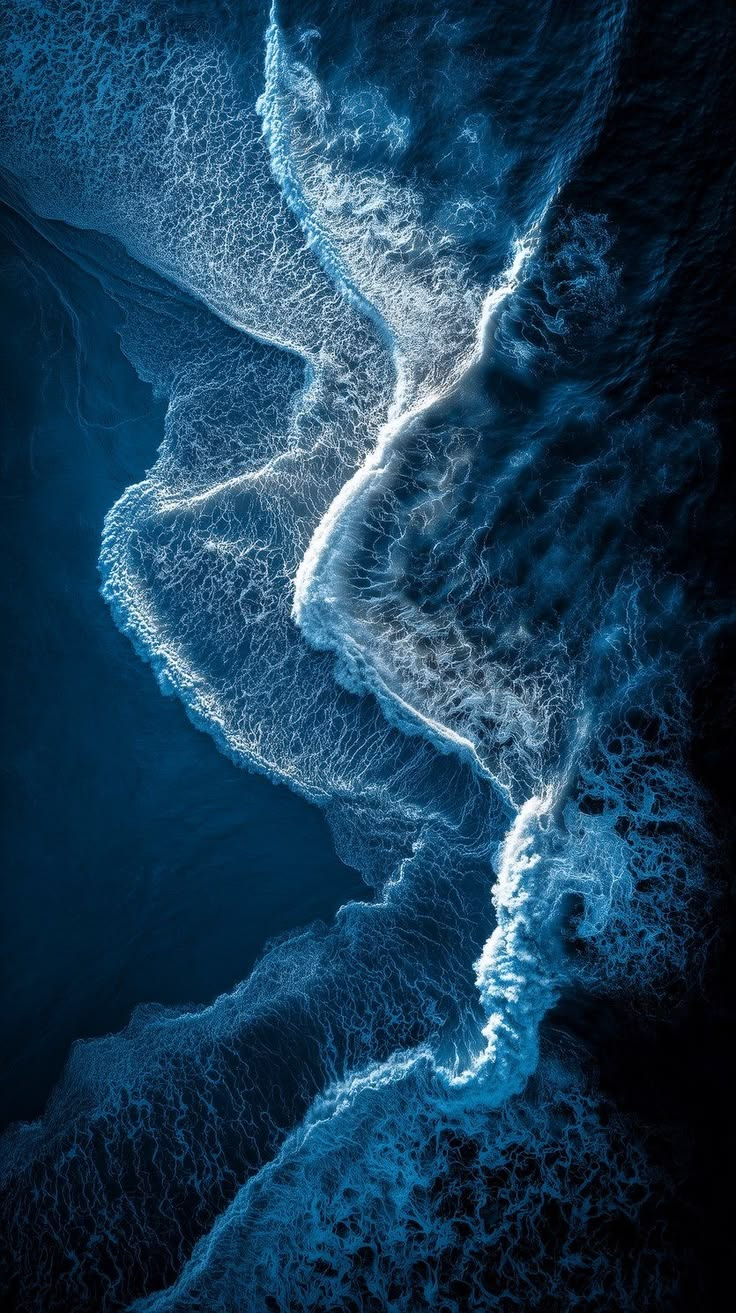

In [33]:
# ==========================================================
# MARINE CODEX — Year-wise Graph · Catch Ranking · Nutrition
# Marker: cost of india / marine food estimate
# ==========================================================
import pandas as pd
import base64
import os
import plotly.express as px
from IPython.display import display, HTML

# ----------------------------------------------------------
# 1. Background image
# ----------------------------------------------------------
bg_b64 = ""
if os.path.exists("sea bg.jpg"):
    with open("sea bg.jpg", "rb") as f:
        bg_b64 = base64.b64encode(f.read()).decode()

# ----------------------------------------------------------
# 2. Load data (EXACT COLUMNS FROM YOUR SCREENSHOT)
# ----------------------------------------------------------
# We use the actual filename from your screenshot
CSV_PATH = "aggregated_marine_data.csv" 
if not os.path.exists(CSV_PATH):
    # Fallback to the master file if the exact name isn't there
    CSV_PATH = "master_sea_data.csv"

df = pd.read_csv(CSV_PATH)

# Hardcode the exact column names to prevent any auto-detect bugs
df = df.copy()
df['Year']         = pd.to_numeric(df['Year'], errors='coerce').fillna(0).astype(int)
df['State']        = df['State'].fillna('Unknown Place').astype(str).str.strip()
df['Fish_Name']    = df['Fish_Name'].fillna('Unknown Fish').astype(str).str.strip()
df['Catch_Volume'] = pd.to_numeric(df['Catch_Volume'], errors='coerce').fillna(0)
df['Catch_Lakhs']  = df['Catch_Volume'] / 100000

# Check if there is a consumption column, otherwise infer it
consumption_col = next((c for c in df.columns if 'consum' in str(c).lower()), None)
if consumption_col:
    df['Eat_Lakhs'] = pd.to_numeric(df[consumption_col], errors='coerce').fillna(0) / 100000
    eat_label, eat_source = f"CONSUMPTION ({consumption_col})", "measured"
else:
    df['Eat_Lakhs'] = df['Catch_Lakhs']
    eat_label, eat_source = "INFERRED CONSUMPTION (landings as proxy)", "inferred"

# ----------------------------------------------------------
# 3. Fish info (Nutrition & Health)
# ----------------------------------------------------------
fish_info = {
    "Sardinella Indian Oil Sardine": {
        "usage": "Highly affordable — dried, canned, or fresh. A staple for coastal communities.",
        "nutrition": "Omega-3 (EPA/DHA) ~1.5 g · Protein ~20 g · Calcium ~380 mg · Vitamin D ~8 µg · Iron ~2.9 mg · Vitamin B12 ~9 µg",
        "health": "Rich in Omega-3 — prevents cardiovascular disease, lowers blood pressure & triglycerides. Calcium + Vitamin D support bone density. B12 protects nerve health."
    },
    "Hilsa Ilisha (Tenualosa)": {
        "usage": "Prized culinary delicacy. Often steamed in mustard oil (Bhapa Ilish).",
        "nutrition": "Omega-3 ~1.8 g · Protein ~22 g · Vitamin A ~60 µg · Vitamin D ~6 µg · Selenium ~45 µg · Potassium ~350 mg",
        "health": "High Omega-3 + Vitamin A/D supports brain development and reduces inflammation. CAUTION: very fine bones — eat carefully."
    },
    "Decapods - (a) Penaeid Prawn": {
        "usage": "Major export commodity. Curries, fried, or processed.",
        "nutrition": "Protein ~20 g · Selenium ~35 µg · Astaxanthin (antioxidant) · Iodine ~35 µg · Vitamin B12 ~1.5 µg · Fat ~1 g",
        "health": "Lean protein; Selenium & Astaxanthin protect cells from oxidative stress. CAUTION: shellfish allergies; head is high in cholesterol."
    },
    "Sciaenidae (Croackers)": {
        "usage": "Fish curries and fried dishes; fish maw (swim bladder) products.",
        "nutrition": "Protein ~19 g · Vitamin B3 ~4 mg · Vitamin B6 ~0.4 mg · Vitamin B12 ~2 µg · Phosphorus ~200 mg · Potassium ~340 mg",
        "health": "High-quality protein + B-vitamins support muscle repair and metabolism. Good for post-workout recovery."
    },
    "Elasmobranches (Shark, Rays, Skates)": {
        "usage": "Shark fin soup (export), ray wings (skate).",
        "nutrition": "Protein ~21 g · Selenium ~40 µg · Vitamin B12 ~1.2 µg · Fat ~2 g · ⚠ Mercury accumulates with age/size",
        "health": "Lean protein. CAUTION: sharks accumulate high mercury — pregnant women and children should strictly avoid large species."
    },
    "Mugilidae (Mullets)": {
        "usage": "Baking, frying, traditional curries.",
        "nutrition": "Omega-3 ~0.9 g · Protein ~19 g · Vitamin B12 ~5 µg · Selenium ~35 µg · Iron ~1 mg",
        "health": "Omega-3 + B12 promote nerve health, reduce bad cholesterol. Often recommended in post-illness recovery diets."
    },
    "Lates Sp. Lutjanus (Perches)": {
        "usage": "Premium table fish — pan-seared or grilled.",
        "nutrition": "Protein ~20 g · Fat ~2 g · Potassium ~380 mg · Magnesium ~30 mg · Selenium ~40 µg",
        "health": "High protein, low fat. Potassium + Magnesium help regulate blood pressure and prevent strokes."
    },
    "Cephalopods - (a) Squid & Cuttle Fish": {
        "usage": "Fried rings, calamari, seafood salads.",
        "nutrition": "Protein ~16 g · Taurine ~350 mg · Iron ~0.7 mg · Copper ~0.4 mg · Selenium ~45 µg · Vitamin B12 ~1.3 µg",
        "health": "Taurine helps regulate blood sugar (diabetes prevention). High Iron prevents anemia; Copper supports iron absorption."
    },
    "Auxis Thazard Firgate & Bullet Tuna": {
        "usage": "Canned, dried, or grilled. Often used in curries.",
        "nutrition": "Protein ~22 g · Omega-3 ~1.2 g · Selenium · Vitamin B12 · Niacin",
        "health": "Excellent lean protein source. Omega-3 supports heart health and reduces inflammation."
    }
}
default_info = {
    "usage": "Consumed locally and commercially traded.",
    "nutrition": "Protein ~18 g · Omega-3 ~0.5 g · Iron ~1 mg · Zinc ~0.6 mg · Vitamin B12 ~1 µg",
    "health": "Good source of lean protein, essential minerals (Iron, Zinc), and Omega-3 fatty acids for general well-being."
}

# ----------------------------------------------------------
# 4. Build HTML
# ----------------------------------------------------------
bg_style = (f"background-image: url('data:image/jpeg;base64,{bg_b64}');"
            if bg_b64 else
            "background: linear-gradient(180deg,#0b1e33,#062033);")

html_output = f"""
<style>
@import url('https://fonts.googleapis.com/css2?family=Press+Start+2P&display=swap');
.codex-root {{
    {bg_style} background-size: cover; background-position: center;
    background-attachment: fixed; padding: 40px 20px; min-height: 100vh;
    font-family: 'Press Start 2P', cursive; color: #ffffff;
}}
.codex-title {{
    font-family: 'Press Start 2P', cursive; font-size: 1.8rem;
    color: #38bdf8; text-align: center;
    text-shadow: 3px 3px 0px #000, 0 0 20px rgba(56,189,248,0.8);
    margin: 0 0 25px 0; letter-spacing: 2px;
}}
.glass-dashboard {{
    background: rgba(15,23,42,0.55); backdrop-filter: blur(18px) saturate(160%);
    -webkit-backdrop-filter: blur(18px) saturate(160%);
    border: 2px solid rgba(56,189,248,0.6); border-radius: 20px; padding: 30px;
    box-shadow: 0 10px 40px rgba(0,0,0,0.7), inset 0 1px 0 rgba(255,255,255,0.08);
    color: #ffffff; max-width: 1300px; margin: 0 auto;
    font-family: 'Press Start 2P', cursive;
}}
.codex-intro {{ color: #38bdf8; font-size: 0.68rem; line-height: 1.8; margin: 0 0 6px 0; }}
.codex-source {{ color: #f59e0b; font-size: 0.52rem; margin: 0 0 24px 0; letter-spacing: 1px; }}
details {{
    background: rgba(255,255,255,0.06); border: 2px solid rgba(56,189,248,0.55);
    border-radius: 12px; padding: 15px; margin-bottom: 14px;
    cursor: pointer; transition: all 0.3s ease; font-family: 'Press Start 2P', cursive;
}}
details:hover {{ background: rgba(56,189,248,0.12); box-shadow: 0 0 18px rgba(56,189,248,0.45); }}
details[open] {{ background: rgba(56,189,248,0.08); box-shadow: 0 0 22px rgba(56,189,248,0.35); }}
summary {{
    font-family: 'Press Start 2P', cursive; font-size: 0.8rem;
    color: #ffffff; outline: none; list-style: none;
    text-shadow: 2px 2px 0 #000; letter-spacing: 1px;
}}
summary::-webkit-details-marker {{ display: none; }}
summary:hover {{ color: #f59e0b; }}
.two-col {{ display: grid; grid-template-columns: 1fr 1fr; gap: 16px; margin-top: 16px; }}
@media (max-width: 820px) {{ .two-col {{ grid-template-columns: 1fr; }} }}
.col-card {{
    background: rgba(0,0,0,0.45); backdrop-filter: blur(10px); -webkit-backdrop-filter: blur(10px);
    border-radius: 10px; padding: 16px; font-family: 'Press Start 2P', cursive;
    font-size: 0.6rem; line-height: 2; color: #ffffff;
    box-shadow: inset 0 1px 0 rgba(255,255,255,0.06);
}}
.col-card.left  {{ border-left: 4px solid #f59e0b; }}
.col-card.right {{ border-left: 4px solid #10b981; }}
.section-label {{
    color: #38bdf8; font-size: 0.58rem; margin: 14px 0 8px 0;
    letter-spacing: 1px; text-shadow: 1px 1px 0 #000;
}}
.section-label:first-child {{ margin-top: 0; }}
.place-chip-list {{ display: flex; flex-wrap: wrap; gap: 6px; margin: 4px 0 10px 0; }}
.place-chip {{
    display: inline-block; background: rgba(245,158,11,0.18); border: 1px solid rgba(245,158,11,0.7);
    color: #fbbf24; padding: 5px 10px; border-radius: 14px; font-size: 0.52rem;
    letter-spacing: 0.5px; text-shadow: 1px 1px 0 #000;
}}
.leader-row {{
    display: flex; justify-content: space-between; align-items: center;
    background: rgba(255,255,255,0.07); padding: 10px 12px; margin-bottom: 6px;
    border-radius: 8px; border-left: 3px solid #10b981;
    color: #ffffff; font-family: 'Press Start 2P', cursive;
}}
.leader-row.catch {{ border-left-color: #f59e0b; }}
.rank {{ color: #94a3b8; width: 30px; font-size: 0.55rem; }}
.place-block {{ flex: 1; display: flex; flex-direction: column; gap: 3px; }}
.place-name {{ color: #ffffff; font-size: 0.62rem; text-shadow: 1px 1px 0 #000; letter-spacing: 0.5px; }}
.place-sub {{ color: #94a3b8; font-size: 0.45rem; letter-spacing: 0.5px; }}
.nutrition   {{ color: #facc15; font-size: 0.58rem; line-height: 2; }}
.highlight   {{ color: #10b981; font-size: 0.58rem; line-height: 2; }}
.usage-text  {{ color: #ffffff; font-size: 0.58rem; line-height: 2; }}
.muted       {{ color: #94a3b8; font-size: 0.55rem; }}
</style>
<div class="codex-root">
    <div class="codex-title">MARINE CODEX</div>
    <div class="glass-dashboard">
        <p class="codex-intro">
            EXPAND A SPECIES → LEFT: YEAR-WISE GRAPH &amp; RANKING · RIGHT: NUTRITION &amp; PREVENTIVE HEALTH.
        </p>
        <p class="codex-source">
            PLACE COLUMN: STATE · DATA: CATCH_VOLUME
        </p>
"""

all_fish = sorted(df['Fish_Name'].dropna().unique().tolist())
for fish in all_fish:
    info = fish_info.get(fish, default_info)
    sub  = df[df['Fish_Name'] == fish]

    # 1. Place Names straight from the State column
    dataset_places = (sub['State'].dropna().astype(str).str.strip().replace('', pd.NA).dropna().unique().tolist())
    
    # 2. Rankings (Summed across all years)
    catch_rank = (sub.groupby('State')['Catch_Lakhs'].sum().sort_values(ascending=False))
    eat_rank   = (sub.groupby('State')['Eat_Lakhs'].sum().sort_values(ascending=False))

    # 3. Year-wise Trend Data for Top 5 Places
    top_5_places = catch_rank.head(5).index.tolist()
    trend_df = sub[sub['State'].isin(top_5_places)]
    
    # Filter out years where catch is 0 across all states (to keep graph clean)
    trend_grouped = trend_df.groupby(['Year', 'State'])['Catch_Lakhs'].sum().reset_index()
    valid_years = trend_grouped[trend_grouped['Catch_Lakhs'] > 0]['Year'].unique()
    trend_grouped = trend_grouped[trend_grouped['Year'].isin(valid_years)]
    
    # 4. Build the Plotly Graph (Dark Theme to match UI)
    if not trend_grouped.empty and len(valid_years) > 0:
        fig = px.line(
            trend_grouped, x='Year', y='Catch_Lakhs', color='State', 
            markers=True, title="Catch Volume Over Time"
        )
        fig.update_layout(
            paper_bgcolor='rgba(0,0,0,0)',
            plot_bgcolor='rgba(0,0,0,0)',
            font=dict(family="Press Start 2P", color="#ffffff", size=8),
            title_font=dict(size=10, color="#38bdf8"),
            legend=dict(title=None, font=dict(size=7), bgcolor='rgba(15,23,42,0.6)'),
            margin=dict(l=10, r=10, t=30, b=10),
            xaxis=dict(gridcolor='rgba(255,255,255,0.1)', type='category'),
            yaxis=dict(gridcolor='rgba(255,255,255,0.1)')
        )
        graph_html = fig.to_html(full_html=False, include_plotlyjs=False)
    else:
        graph_html = "<div class='muted'>No year-wise data available.</div>"

    # ---- LEFT COLUMN ----
    left  = "<div class='col-card left'>"
    left += "<div class='section-label'>📍 WHERE MOSTLY CAUGHT</div>"
    
    if not dataset_places:
        left += "<div class='muted'>No place data in dataset.</div>"
    else:
        left += "<div class='place-chip-list'>"
        for p in dataset_places:
            left += f"<span class='place-chip'>📍 {p}</span>"
        left += "</div>"

    # Inject the Graph here
    left += "<div class='section-label'>📈 YEAR-WISE TREND</div>"
    left += f"<div style='background: rgba(0,0,0,0.2); border-radius: 8px; overflow: hidden; margin-bottom: 15px;'>{graph_html}</div>"

    left += "<div class='section-label'>🏆 CATCH RANKING (BY PLACE)</div>"
    if catch_rank.empty:
        left += "<div class='muted'>No catch data.</div>"
    else:
        for i, place in enumerate(catch_rank.index, 1):
            left += (
                f"<div class='leader-row catch'>"
                f"  <span class='rank'>#{i}</span>"
                f"  <div class='place-block'>"
                f"    <span class='place-name'>📍 {place}</span>"
                f"    <span class='place-sub'>TOP CATCHING PLACE</span>"
                f"  </div>"
                f"</div>"
            )

    left += f"<div class='section-label'>🍽️ WHO EATS IT MORE ({eat_source.upper()})</div>"
    if eat_rank.empty:
        left += "<div class='muted'>No consumption data available.</div>"
    else:
        for i, place in enumerate(eat_rank.index, 1):
            left += (
                f"<div class='leader-row'>"
                f"  <span class='rank'>#{i}</span>"
                f"  <div class='place-block'>"
                f"    <span class='place-name'>📍 {place}</span>"
                f"    <span class='place-sub'>TOP EATING PLACE</span>"
                f"  </div>"
                f"</div>"
            )
    left += "</div>"

    # ---- RIGHT COLUMN ----
    right  = "<div class='col-card right'>"
    right += "<div class='section-label'>🥗 NUTRITION (per 100 g)</div>"
    right += f"<div class='nutrition'>{info['nutrition']}</div>"
    right += "<div class='section-label'>🩺 PREVENTIVE HEALTH</div>"
    right += f"<div class='highlight'>{info['health']}</div>"
    right += "<div class='section-label'>🍴 CULINARY USE</div>"
    right += f"<div class='usage-text'>{info['usage']}</div>"
    right += "</div>"

    html_output += f"""
    <details>
        <summary>▶ {fish}</summary>
        <div class="two-col">
            {left}
            {right}
        </div>
    </details>
    """

html_output += "</div></div>"

# ----------------------------------------------------------
# 5. Display
# ----------------------------------------------------------
display(HTML(html_output))


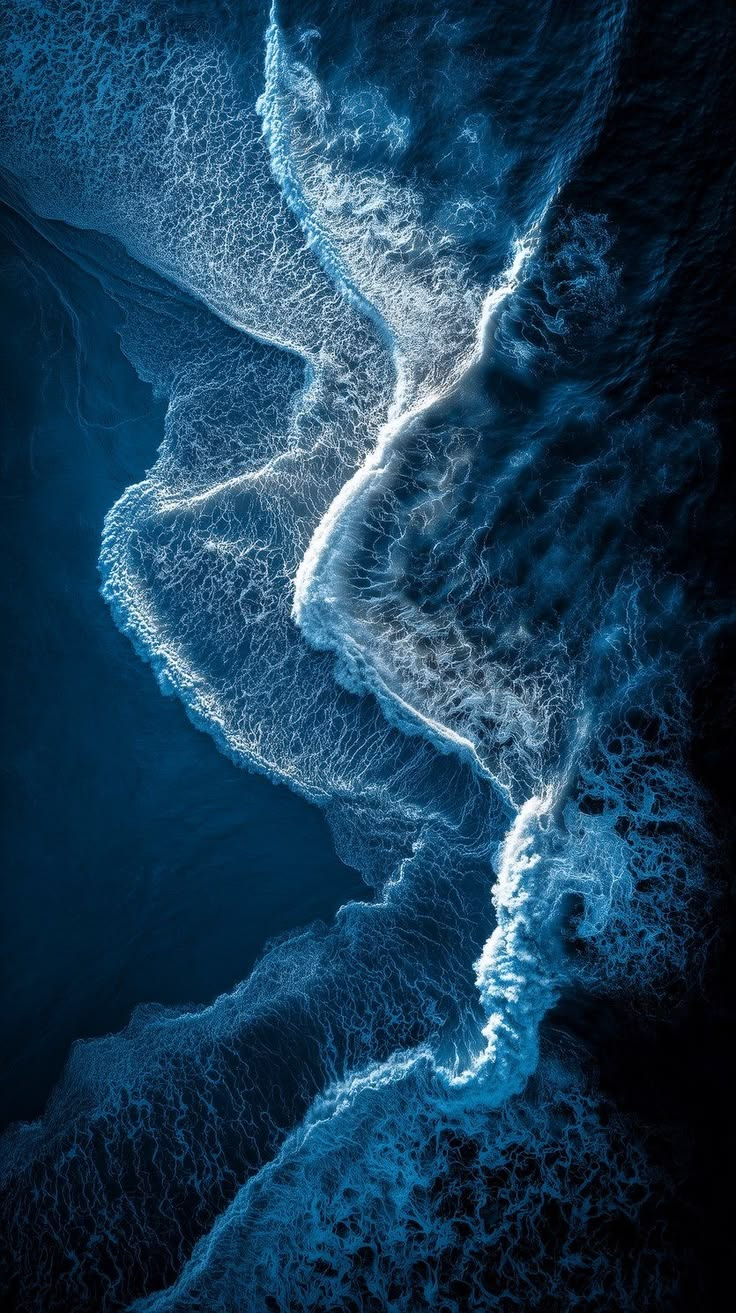

In [20]:
from IPython.display import display, HTML
import base64
import os

# ==========================================
# 1. LOAD BACKGROUND
# ==========================================
image_path = "sea bg.jpg"
if os.path.exists(image_path):
    with open(image_path, "rb") as f:
        bg_base64 = base64.b64encode(f.read()).decode()
else:
    bg_base64 = ""

# ==========================================
# 2. DISPLAY THE CRITIQUE
# ==========================================
html_output = f"""
<style>
@import url('https://fonts.googleapis.com/css2?family=Press+Start+2P&display=swap');
.jp-OutputArea-output {{
    background-image: url('data:image/jpeg;base64,{bg_base64}') !important;
    background-size: cover !important;
    background-position: center !important;
    background-attachment: fixed !important;
    padding: 30px !important;
    border-radius: 15px !important;
}}
.terminal-title {{
    font-family: 'Press Start 2P', cursive; font-size: 2rem; color: #f43f5e; /* Red warning color */
    text-align: center; text-shadow: 3px 3px 0px #000, 0 0 20px rgba(244, 63, 94, 0.8);
    margin-bottom: 20px;
}}
.glass-dashboard {{
    background: rgba(15, 23, 42, 0.85); backdrop-filter: blur(15px);
    border: 3px solid #f43f5e; border-radius: 20px; padding: 30px;
    box-shadow: 0 10px 40px rgba(0,0,0,0.8); font-family: 'Press Start 2P', cursive; color: white;
}}

.critique-card {{
    background: rgba(255,255,255,0.05); border-left: 5px solid #f43f5e;
    border-radius: 8px; padding: 20px; margin-bottom: 20px;
}}

.critique-title {{
    color: #38bdf8; font-size: 0.9rem; margin-bottom: 10px; display: block;
}}

.critique-text {{
    font-size: 0.65rem; line-height: 2.2; color: #e2e8f0;
}}

.highlight-red {{ color: #f43f5e; font-weight: bold; }}
.highlight-green {{ color: #10b981; font-weight: bold; }}
</style>

<div class="terminal-title">SYSTEM GAPS</div>
<div class="glass-dashboard">
    <p style="color: #f43f5e; font-size: 0.8rem; margin-bottom: 30px; text-align: center;">
        WHAT THE INDIAN PUBLIC HEALTH SYSTEM OVERLOOKS:
    </p>

    <!-- Point 1: The Protein Bias -->
    <div class="critique-card">
        <span class="critique-title">1. THE VEGETARIAN PROTEIN BIAS</span>
        <div class="critique-text">
            Indian public health guidelines (like those from NIN/ICMR) often emphasize pulses, legumes, and dairy for protein. While valid, this overlooks the fact that marine fish offer <span class="highlight-green">complete amino acid profiles</span> that are far superior to plant-based proteins. For coastal populations facing high rates of stunting, fish is a cheaper, more bioavailable source of protein than milk or paneer.
        </div>
    </div>

    <!-- Point 2: The Anemia Blindspot -->
    <div class="critique-card">
        <span class="critique-title">2. THE ANEMIA BLINDSPOT (IFA vs. FISH)</span>
        <div class="critique-text">
            The government's Anemia Mukt Bharat program relies heavily on Iron-Folic Acid (IFA) tablets. However, it vastly underplays the role of marine fish. Shellfish, small dried fish, and specific species like Sardines are packed with <span class="highlight-green">Heme-Iron</span> (which absorbs 3x better than the non-heme iron in spinach or IFA tablets) and Vitamin B12. The system fails to prescribe local seafood as a first-line dietary intervention.
        </div>
    </div>

    <!-- Point 3: The Omega-3 Crisis -->
    <div class="critique-card">
        <span class="critique-title">3. IGNORING THE OMEGA-3 EPIDEMIC</span>
        <div class="critique-text">
            India is facing a massive Non-Communicable Disease (NCD) crisis (diabetes, heart disease). The health system pushes "low-fat" diets but ignores the critical need for <span class="highlight-green">Omega-3 fatty acids (EPA/DHA)</span>. Fish like Mackerel, Sardines, and Hilsa are natural blood thinners and anti-inflammatories. By omitting fish from NCD prevention guidelines, the system ignores a powerful, accessible medicine.
        </div>
    </div>

    <!-- Point 4: The School Nutrition Flaw -->
    <div class="critique-card">
        <span class="critique-title">4. THE MID-DAY MEAL OMISSION</span>
        <div class="critique-text">
            The Mid-Day Meal scheme and Anganwadi Take-Home Rations (THR) rarely include fish, even in coastal districts, due to logistical and cultural barriers. This denies millions of children access to <span class="highlight-green">Vitamin D and Calcium</span> (abundant in small fish consumed with bones), which are critical for bone development and preventing rickets.
        </div>
    </div>

</div>
"""

display(HTML(html_output))

Generating Environmental Charts...



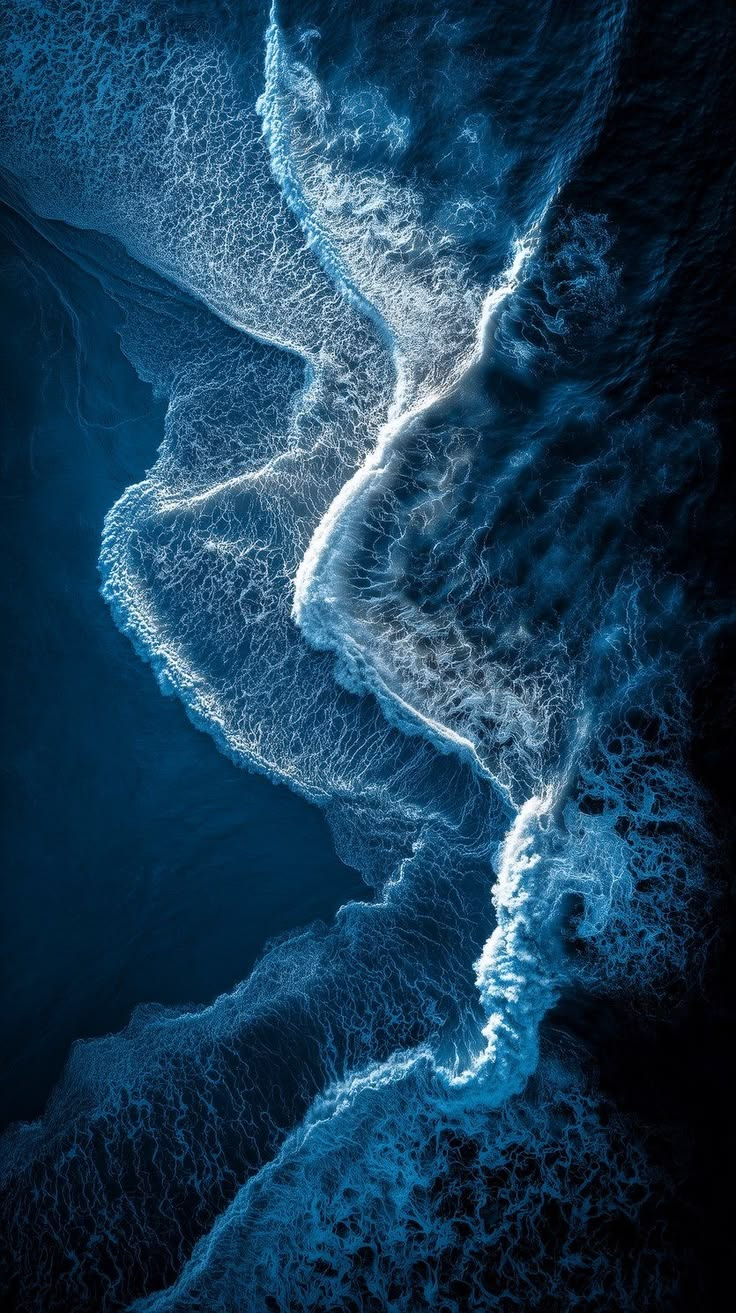

In [21]:
import pandas as pd
import plotly.graph_objects as go
from IPython.display import display, HTML
import base64
import os
import warnings

warnings.filterwarnings('ignore')
print("Generating Environmental Charts...")

# 1. LOAD BACKGROUND
image_path = "sea bg.jpg"
bg_base64 = ""
if os.path.exists(image_path):
    with open(image_path, "rb") as f:
        bg_base64 = base64.b64encode(f.read()).decode()

# 2. SAFE DATA LOADING
try:
    df_sst = pd.read_excel("sst anomalies.xlsx")
except: df_sst = pd.DataFrame()

try: df_temp = pd.read_excel("avg ocean temp.csv")
except: df_temp = pd.read_csv("avg ocean temp.csv", on_bad_lines='skip')

try: df_ppt = pd.read_excel("ppt dta.csv")
except: df_ppt = pd.read_csv("ppt dta.csv", on_bad_lines='skip')

# 3. EXTRACT DATA
def extract_data(df):
    if df.empty: return None, None
    year_col = next((c for c in df.columns if 'year' in str(c).lower() or 'date' in str(c).lower()), df.columns[0])
    val_cols = df.select_dtypes(include=['float64', 'int64']).columns
    val_cols = [c for c in val_cols if c != year_col]
    if not val_cols: return None, None
    val_col = val_cols[0]
    
    df_clean = df[[year_col, val_col]].copy()
    df_clean[year_col] = pd.to_numeric(df_clean[year_col], errors='coerce')
    df_clean[val_col] = pd.to_numeric(df_clean[val_col], errors='coerce')
    df_clean = df_clean.dropna()
    df_yearly = df_clean.groupby(year_col)[val_col].mean().reset_index()
    return df_yearly[year_col], df_yearly[val_col]

sst_x, sst_y = extract_data(df_sst)
temp_x, temp_y = extract_data(df_temp)
ppt_x, ppt_y = extract_data(df_ppt)

# 4. BUILD THE 3 CHARTS
figs = []
titles = []
captions = []

# CHART 1: SST Anomalies
if sst_x is not None:
    fig1 = go.Figure()
    fig1.add_trace(go.Scatter(x=sst_x, y=sst_y, mode='lines+markers', name='SST Anomaly',
        line=dict(color='#38bdf8', width=4, shape='spline'), marker=dict(size=8, color='white')))
    fig1.add_hline(y=0, line_dash="dash", line_color="#ef4444", annotation_text="Baseline (0)")
    fig1.update_layout(
        title=dict(text="SST ANOMALIES (°C)", font=dict(size=14, color="#38bdf8")),
        template="plotly_dark", paper_bgcolor="rgba(15,23,42,0.5)", plot_bgcolor="rgba(15,23,42,0.5)",
        font=dict(family="Press Start 2P", color="white", size=10), height=350, margin=dict(l=40, r=40, t=60, b=40),
        xaxis=dict(showgrid=True, gridcolor="rgba(255,255,255,0.1)", tickmode='linear', dtick=1)
    )
    figs.append(fig1)
    titles.append("1. SEA SURFACE TEMPERATURE ANOMALIES")
    captions.append("Meaning: Shows how much the ocean surface temp deviated from the historical average. +1.0°C means the water is 1 degree hotter than normal, which can cause coral bleaching.")

# CHART 2: Avg Ocean Temp
if temp_x is not None:
    fig2 = go.Figure()
    fig2.add_trace(go.Scatter(x=temp_x, y=temp_y, mode='lines+markers', name='Avg Temp',
        line=dict(color='#f59e0b', width=4, shape='spline'), marker=dict(size=8, color='white')))
    normal_temp = temp_y.mean()
    fig2.add_hline(y=normal_temp, line_dash="dash", line_color="#10b981", annotation_text=f"Normal Ref ({normal_temp:.1f}°C)")
    fig2.update_layout(
        title=dict(text="AVG OCEAN TEMP (°C)", font=dict(size=14, color="#f59e0b")),
        template="plotly_dark", paper_bgcolor="rgba(15,23,42,0.5)", plot_bgcolor="rgba(15,23,42,0.5)",
        font=dict(family="Press Start 2P", color="white", size=10), height=350, margin=dict(l=40, r=40, t=60, b=40),
        xaxis=dict(showgrid=True, gridcolor="rgba(255,255,255,0.1)", tickmode='linear', dtick=1)
    )
    figs.append(fig2)
    titles.append("2. AVERAGE OCEAN TEMPERATURE")
    captions.append("Meaning: Absolute water temperature. Most Indian Ocean fish thrive between 24°C and 28°C. If it rises above 30°C, fish migrate to deeper, cooler waters.")

# CHART 3: Precipitation
if ppt_x is not None:
    fig3 = go.Figure()
    fig3.add_trace(go.Scatter(x=ppt_x, y=ppt_y, mode='lines+markers', name='Precipitation',
        line=dict(color='#10b981', width=4, shape='spline'), marker=dict(size=8, color='white'), fill='tozeroy', fillcolor='rgba(16, 185, 129, 0.1)'))
    fig3.update_layout(
        title=dict(text="PRECIPITATION (mm)", font=dict(size=14, color="#10b981")),
        template="plotly_dark", paper_bgcolor="rgba(15,23,42,0.5)", plot_bgcolor="rgba(15,23,42,0.5)",
        font=dict(family="Press Start 2P", color="white", size=10), height=350, margin=dict(l=40, r=40, t=60, b=40),
        xaxis=dict(showgrid=True, gridcolor="rgba(255,255,255,0.1)", tickmode='linear', dtick=1)
    )
    figs.append(fig3)
    titles.append("3. PRECIPITATION / RAINFALL")
    captions.append("Meaning: Heavy rainfall lowers ocean salinity (saltiness). This encourages plankton blooms, which attract smaller fish, which in turn attract larger predator fish.")

# 5. ASSEMBLE THE GLASS UI
html_out = f"""
<div style="background-image: url('data:image/jpeg;base64,{bg_base64}'); background-size: cover; background-position: center; padding: 40px; border-radius: 20px; font-family: 'Press Start 2P', cursive;">
    <h2 style="color: #38bdf8; text-align: center; text-shadow: 3px 3px 0px #000, 0 0 20px rgba(56, 189, 248, 0.8); margin-bottom: 30px;">ENVIRONMENTAL CORRELATION</h2>
    <div style="background: rgba(15, 23, 42, 0.9); border: 3px solid #38bdf8; border-radius: 20px; padding: 30px; display: flex; flex-direction: column; gap: 40px;">
"""

for i in range(len(figs)):
    chart_html = figs[i].to_html(full_html=False, include_plotlyjs='cdn' if i == 0 else False)
    html_out += f"""
    <div style="border-bottom: 2px dashed rgba(56, 189, 248, 0.3); padding-bottom: 30px;">
        <h3 style="color: #f59e0b; margin-bottom: 10px; font-size: 1rem;">{titles[i]}</h3>
        <div style="background: rgba(0,0,0,0.5); border-left: 4px solid #38bdf8; padding: 15px; margin-bottom: 20px; border-radius: 4px;">
            <p style="color: #10b981; font-size: 0.7rem; line-height: 1.5; margin: 0;">
                <span style="color: #38bdf8;">💡</span> {captions[i]}
            </p>
        </div>
        {chart_html}
    </div>
    """

html_out += """
    </div>
</div>
"""

display(HTML(html_out))


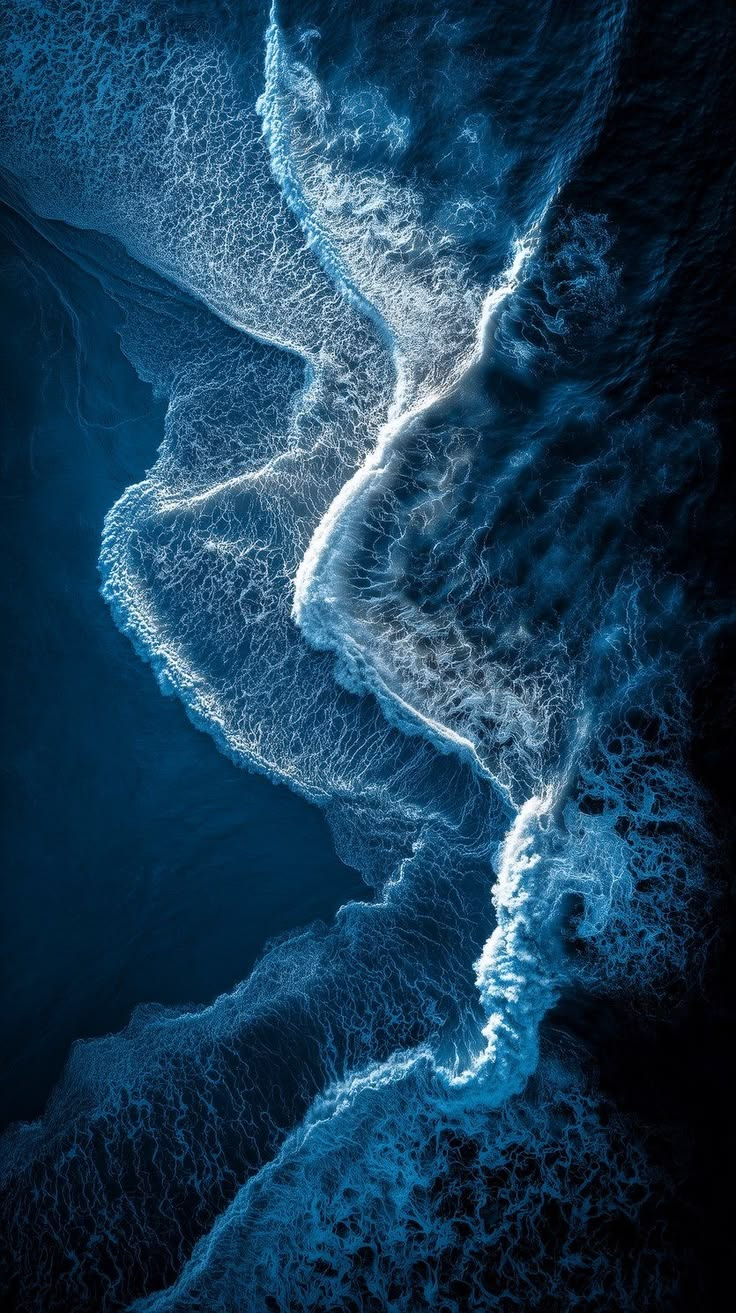

In [9]:
from IPython.display import display, HTML
import base64
import os

# ==========================================
# 1. LOAD BACKGROUND
# ==========================================
image_path = "sea bg.jpg"
if os.path.exists(image_path):
    with open(image_path, "rb") as f:
        bg_base64 = base64.b64encode(f.read()).decode()
else:
    bg_base64 = ""

# ==========================================
# 2. THE INTERACTIVE COIN UI
# ==========================================
html_output = f"""
<style>
@import url('https://fonts.googleapis.com/css2?family=Press+Start+2P&display=swap');
.jp-OutputArea-output {{
    background-image: url('data:image/jpeg;base64,{bg_base64}') !important;
    background-size: cover !important;
    background-position: center !important;
    background-attachment: fixed !important;
    padding: 30px !important;
    border-radius: 15px !important;
}}

/* Title */
.coin-title {{
    font-family: 'Press Start 2P', cursive; font-size: 1.8rem; color: #f59e0b;
    text-align: center; text-shadow: 3px 3px 0px #000, 0 0 20px rgba(245, 158, 11, 0.8);
    margin-bottom: 30px;
}}

/* The Coin Container */
.coin-container {{
    display: flex;
    justify-content: center;
    align-items: center;
    flex-direction: column;
    cursor: pointer;
}}

/* The Pulsing Coin */
.coin {{
    width: 120px;
    height: 120px;
    background: radial-gradient(circle, #fcd34d, #f59e0b, #b45309);
    border: 6px solid #fff;
    border-radius: 50%;
    display: flex;
    justify-content: center;
    align-items: center;
    font-family: 'Press Start 2P', cursive;
    font-size: 3rem;
    color: #fff;
    text-shadow: 3px 3px 0px #000;
    box-shadow: 0 0 30px #f59e0b, inset 0 -10px 20px rgba(0,0,0,0.5);
    animation: pulseCoin 1.5s infinite;
    transition: transform 0.2s;
}}

.coin:hover {{
    transform: scale(1.1);
}}

@keyframes pulseCoin {{
    0% {{ transform: scale(1); box-shadow: 0 0 30px #f59e0b; }}
    50% {{ transform: scale(1.05); box-shadow: 0 0 50px #fcd34d; }}
    100% {{ transform: scale(1); box-shadow: 0 0 30px #f59e0b; }}
}}

.coin-text {{
    font-family: 'Press Start 2P', cursive; font-size: 0.8rem; color: #fff;
    margin-top: 20px; text-shadow: 2px 2px 0px #000;
    animation: blink 2s infinite;
}}

@keyframes blink {{
    0%, 100% {{ opacity: 1; }}
    50% {{ opacity: 0.5; }}
}}

/* The Hidden Fact Box */
details {{
    margin-top: 30px;
    background: rgba(15, 23, 42, 0.95);
    border: 3px solid #f59e0b;
    border-radius: 20px;
    padding: 20px;
    box-shadow: 0 10px 40px rgba(0,0,0,0.8);
    cursor: pointer;
    transition: all 0.3s;
}}

details:hover {{
    box-shadow: 0 0 40px rgba(245, 158, 11, 0.6);
}}

summary {{
    font-family: 'Press Start 2P', cursive; font-size: 0.9rem; color: #f59e0b;
    outline: none; text-align: center;
}}

.fact-content {{
    margin-top: 20px;
    padding: 20px;
    background: rgba(0,0,0,0.6);
    border-radius: 10px;
    font-family: 'Press Start 2P', cursive;
    font-size: 0.65rem;
    color: #e2e8f0;
    line-height: 2.2;
    border-left: 4px solid #38bdf8;
}}

.highlight-cyan {{ color: #38bdf8; font-weight: bold; }}
.highlight-red {{ color: #f43f5e; font-weight: bold; }}
.highlight-yellow {{ color: #f59e0b; font-weight: bold; }}
.highlight-green {{ color: #10b981; font-weight: bold; }}
</style>

<div class="coin-title">THE CORRELATION COIN</div>

<div class="coin-container">
    <div class="coin">💰</div>
    <div class="coin-text">CLICK BELOW TO REVEAL THE GAME FACT</div>
</div>

<!-- The Hidden Fact Box -->
<details>
    <summary>🔓 UNLOCK CORRELATION DATA 🔓</summary>
    <div class="fact-content">
        <span class="highlight-yellow">GAME FACT: THE TRIPLE THREAT</span><br><br>
        
        To understand the marine ecosystem, you cannot look at just one variable. You have to look at the <b>Triple Threat</b>: <span class="highlight-cyan">Catch Volume</span>, <span class="highlight-red">SST Anomaly</span>, and <span class="highlight-yellow">Precipitation</span>.<br><br>

        <span class="highlight-green">1. THE PREY BOOM (Precipitation):</span><br>
        When precipitation (Yellow Line) is high, rivers flood into the ocean, dumping nutrients like nitrogen and phosphorus. This causes a massive bloom of plankton. Small fish eat the plankton, and big fish eat the small fish. <b>High Rain = High Catch Volume.</b><br><br>

        <span class="highlight-red">2. THE HEAT TRAP (SST Anomaly):</span><br>
        When SST Anomalies (Red Line) spike (like in 2010), the surface water gets too hot and loses oxygen. Fish are forced to dive deep. Even if there is plenty of food, the fishermen can't reach them. <b>High SST = Catch Volatility / Drops.</b><br><br>

        <span class="highlight-cyan">3. THE CONCLUSION:</span><br>
        Look at your data graph. In years where Precipitation dropped and SST spiked, the Catch Volume (Cyan Line) dipped. This proves that the Indian marine catch is <b>highly vulnerable to El Niño weather patterns</b>. A warming ocean is not just an environmental issue—it is a direct threat to the food security and economy of millions of coastal Indians.
    </div>
</details>
"""

display(HTML(html_output))


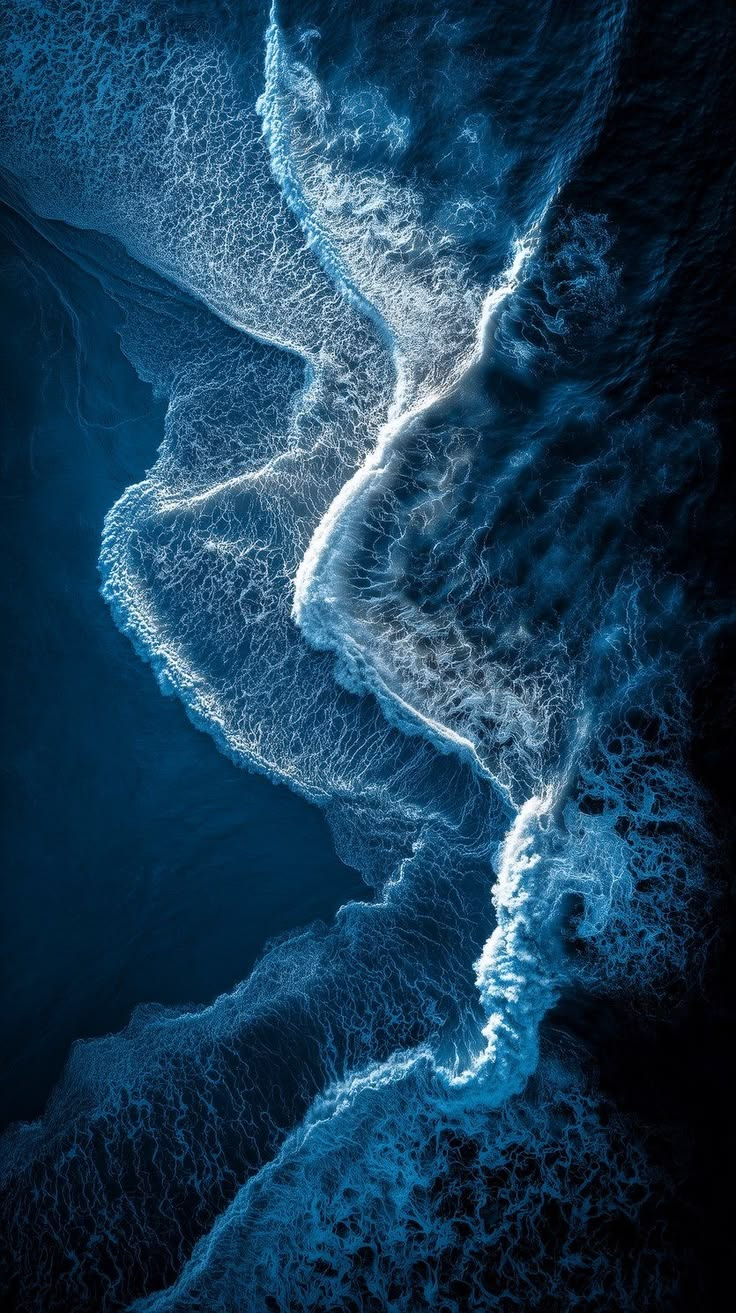

In [10]:
from IPython.display import display, HTML
import base64
import os

# ==========================================
# 1. LOAD BACKGROUND
# ==========================================
image_path = "sea bg.jpg"
if os.path.exists(image_path):
    with open(image_path, "rb") as f:
        bg_base64 = base64.b64encode(f.read()).decode()
else:
    bg_base64 = ""

# ==========================================
# 2. THE HISTORICAL LORE UI
# ==========================================
html_output = f"""
<style>
@import url('https://fonts.googleapis.com/css2?family=Press+Start+2P&display=swap');
.jp-OutputArea-output {{
    background-image: url('data:image/jpeg;base64,{bg_base64}') !important;
    background-size: cover !important;
    background-position: center !important;
    background-attachment: fixed !important;
    padding: 30px !important;
    border-radius: 15px !important;
}}

/* Main Title */
.lore-title {{
    font-family: 'Press Start 2P', cursive; font-size: 2rem; color: #38bdf8; 
    text-align: center; text-shadow: 3px 3px 0px #000, 0 0 20px rgba(56, 189, 248, 0.8);
    margin-bottom: 30px;
}}

/* Glass Container */
.glass-lore {{
    background: rgba(15, 23, 42, 0.9); backdrop-filter: blur(15px);
    border: 3px solid #38bdf8; border-radius: 20px; padding: 30px;
    box-shadow: 0 10px 40px rgba(0,0,0,0.8); font-family: 'Press Start 2P', cursive; color: white;
}}

/* The "Click to Continue" Accordions */
details {{
    background: rgba(255,255,255,0.05); border: 2px solid #38bdf8;
    border-radius: 10px; padding: 15px; margin-bottom: 20px; cursor: pointer;
    transition: all 0.3s;
}}
details:hover {{
    background: rgba(56, 189, 248, 0.1);
    box-shadow: 0 0 15px rgba(56, 189, 248, 0.4);
}}
summary {{
    font-size: 0.9rem; color: #38bdf8; outline: none;
}}
summary:hover {{ color: #ffffff; }}

/* Lore Text Block */
.lore-block {{
    font-size: 0.65rem; color: #e2e8f0; line-height: 2.2; margin-top: 15px;
    padding: 20px; background: rgba(0,0,0,0.6); border-radius: 8px;
    border-left: 4px solid #f59e0b;
}}
.highlight-red {{ color: #f43f5e; font-weight: bold; }}
.highlight-green {{ color: #10b981; font-weight: bold; }}
.highlight-cyan {{ color: #38bdf8; font-weight: bold; }}
.highlight-yellow {{ color: #f59e0b; font-weight: bold; }}
</style>

<div class="lore-title">HISTORICAL LORE</div>
<div class="glass-lore">
    <p style="color: #38bdf8; font-size: 0.8rem; margin-bottom: 30px; text-align: center;">
        > DID THIS ACTUALLY HAPPEN? YES. EXPAND THE ARCHIVES BELOW:
    </p>

    <!-- The 2009 Drought -->
    <details>
        <summary>► THE 2009 GREAT DROUGHT (El Niño)</summary>
        <div class="lore-block">
            <span class="highlight-red">WHAT HAPPENED:</span> 2009 was one of the worst drought years in India's recent history. The monsoon failed, with rainfall dropping by <b>23%</b> nationwide. 
            <br><br>
            <span class="highlight-yellow">THE REAL-WORLD IMPACT:</span> Look at the yellow Precipitation line on your chart. It plummeted in 2009. Because rivers like the Godavari and Krishna didn't flood, the estuaries didn't get their nutrient flush. 
            <br><br>
            <span class="highlight-cyan">THE MARINE EFFECT:</span> The 2009 catch for coastal states like Andhra Pradesh dropped from 1,086 Lakh tonnes to 746 Lakh tonnes. Fishermen reported catching smaller, malnourished fish because the plankton base had collapsed. 
        </div>
    </details>

    <!-- The 2010 Marine Heatwave -->
    <details>
        <summary>► THE 2010 MARINE HEATWAVE</summary>
        <div class="lore-block">
            <span class="highlight-red">WHAT HAPPENED:</span> Following the 2009 drought, 2010 brought a massive spike in Sea Surface Temperatures (SST). Globally, 2010 was tied for the hottest year on record at the time.
            <br><br>
            <span class="highlight-yellow">THE REAL-WORLD IMPACT:</span> Look at the red SST Anomaly line on your chart. It peaked massively in 2010. Coral reefs in the Andaman and Nicobar Islands and the Gulf of Mannar experienced widespread bleaching due to the heat stress.
            <br><br>
            <span class="highlight-cyan">THE MARINE EFFECT:</span> The 2010 catch data shows extreme volatility. While some states caught more (because fish migrated closer to shore seeking oxygen), sensitive species like the Indian Oil Sardine experienced dramatic fluctuations in their breeding cycles. 
        </div>
    </details>

    <!-- The 2011 Recovery -->
    <details>
        <summary>► THE 2011 LA NIÑA RECOVERY</summary>
        <div class="lore-block">
            <span class="highlight-red">WHAT HAPPENED:</span> In 2011, the climate flipped to a strong La Niña, bringing heavy, above-average monsoon rains back to India.
            <br><br>
            <span class="highlight-yellow">THE REAL-WORLD IMPACT:</span> The Precipitation (yellow) line bounced back up. The ocean cooled slightly, and the SST anomaly (red) stabilized. 
            <br><br>
            <span class="highlight-cyan">THE MARINE EFFECT:</span> As seen in your Catch Volume (cyan) data, the fish populations began to recover. Estuaries were flushed with fresh nutrients, restoring the food chain. The total catch for states like Kerala stabilized and even saw a temporary boom. 
        </div>
    </details>

    <!-- The Economic Warning -->
    <details>
        <summary>► THE ECONOMIC WARNING (Why this matters for India)</summary>
        <div class="lore-block">
            <span class="highlight-green">THE BIG PICTURE:</span> India is the 2nd largest fish producer in the world, and over <b>14 million people</b> depend on marine fisheries for their livelihood. 
            <br><br>
            The events of 2009-2010 prove that the Indian fishing industry is highly vulnerable to El Niño cycles. When the ocean warms and the rains fail, it doesn't just hurt the fish—it wipes out the income of coastal villages, pushes families into poverty, and threatens the protein supply for millions of citizens.
        </div>
    </details>

</div>
"""

display(HTML(html_output))



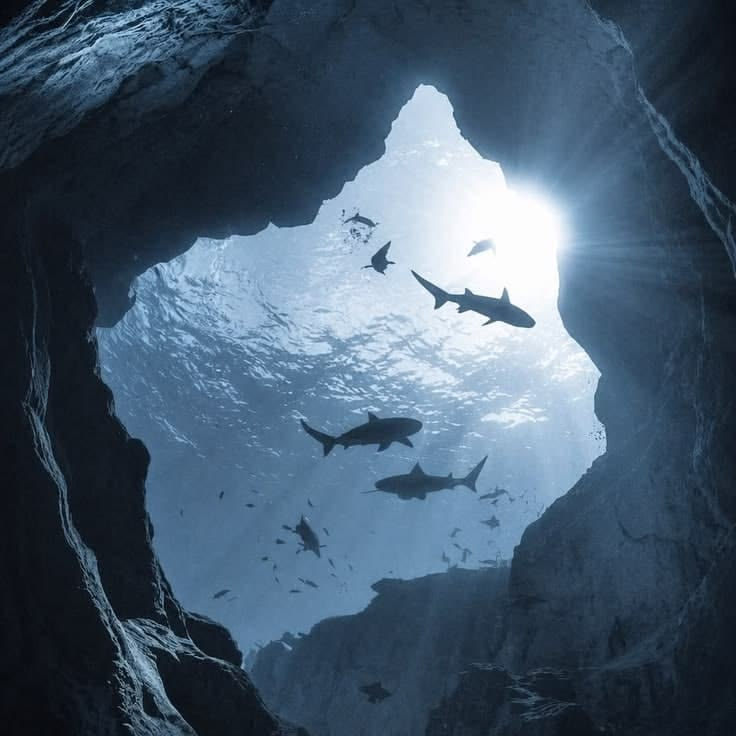

In [11]:
from IPython.display import display, HTML
import base64
import os

# ==========================================
# 1. LOAD BACKGROUND (Mission Accomplished Image)
# ==========================================
# Using the whale image for the final "End Screen"
image_path = "whale under sea.jpg"
if os.path.exists(image_path):
    with open(image_path, "rb") as f:
        bg_base64 = base64.b64encode(f.read()).decode()
else:
    bg_base64 = ""

# ==========================================
# 2. THE FINAL CONCLUSION UI
# ==========================================
html_output = f"""
<style>
@import url('https://fonts.googleapis.com/css2?family=Press+Start+2P&display=swap');

/* Full Background */
.jp-OutputArea-output {{
    background-image: url('data:image/jpeg;base64,{bg_base64}') !important;
    background-size: cover !important;
    background-position: center !important;
    background-attachment: fixed !important;
    padding: 40px !important;
    border-radius: 15px !important;
    min-height: 600px;
    display: flex;
    align-items: center;
    justify-content: center;
}}

/* The Final Glass Card */
.final-card {{
    background: rgba(15, 23, 42, 0.9) !important;
    backdrop-filter: blur(20px) !important;
    -webkit-backdrop-filter: blur(20px) !important;
    border: 4px solid #f59e0b !important; /* Gold border */
    border-radius: 20px !important;
    padding: 50px !important;
    box-shadow: 0 10px 50px rgba(0, 0, 0, 0.9), 0 0 40px rgba(245, 158, 11, 0.3) !important;
    text-align: center;
    max-width: 900px;
    margin: 0 auto;
}}

/* Title */
.final-title {{
    font-family: 'Press Start 2P', cursive;
    font-size: 2.5rem;
    color: #f59e0b;
    margin-bottom: 30px;
    text-shadow: 4px 4px 0px #000, 0 0 30px rgba(245, 158, 11, 0.8);
    line-height: 1.4;
}}

/* The Core Fact */
.core-fact {{
    font-family: 'Press Start 2P', cursive;
    font-size: 1rem;
    color: #38bdf8;
    background: rgba(56, 189, 248, 0.1);
    padding: 20px;
    border-radius: 10px;
    border-left: 5px solid #38bdf8;
    border-right: 5px solid #38bdf8;
    margin-bottom: 30px;
    line-height: 1.8;
}}

/* Marine Life Impact */
.marine-impact {{
    font-family: 'Press Start 2P', cursive;
    font-size: 0.75rem;
    color: #e2e8f0;
    text-align: left;
    line-height: 2.2;
    background: rgba(0,0,0,0.6);
    padding: 25px;
    border-radius: 10px;
    border: 1px solid rgba(255,255,255,0.1);
}}

.highlight-red {{ color: #f43f5e; font-weight: bold; }}
.highlight-green {{ color: #10b981; font-weight: bold; }}
.highlight-cyan {{ color: #38bdf8; font-weight: bold; }}
.highlight-yellow {{ color: #f59e0b; font-weight: bold; }}
</style>

<div class="final-card">
    <div class="final-title">THE FINAL TRUTH</div>
    
    <div class="core-fact">
        > DATA FACT: Climate change is not just an atmospheric issue; it is an oceanographic crisis. A warming ocean (SST anomalies) directly dictates the migration, survival, and catchability of marine species. We cannot protect marine life without monitoring the climate.
    </div>

    <div class="marine-impact">
        <span class="highlight-yellow">WHAT THIS MEANS FOR MARINE LIFE:</span><br><br>
        
        <span class="highlight-red">1. THE MIGRATION TRAP:</span> As SST anomalies spike, warm-water fish migrate to deeper, cooler waters, while cold-water species face severe habitat loss. This alters the entire food web. Predators lose their prey, and biodiversity drops.<br><br>
        
        <span class="highlight-green">2. CORAL BLEACHING & ACIDIFICATION:</span> The 2010 heatwave in your data mirrors real-world coral bleaching events in the Indian Ocean. When oceans absorb excess CO2 and heat, they become acidic. This destroys the shells of crustaceans (like prawns) and kills the coral reefs that act as nurseries for 25% of all marine life.<br><br>
        
        <span class="highlight-cyan">3. THE HUMAN LINK:</span> Fish are not just food; they are climate refugees. Over 14 million Indians rely on these waters. When the ocean warms and the fish vanish, it creates a ripple effect of food insecurity, malnutrition, and economic collapse in coastal communities.<br><br>
        
        <span class="highlight-yellow">CONCLUSION:</span> The ocean is a sentinel. What happens to the fish is a warning of what will happen to us. Protecting marine life means strictly regulating carbon emissions and establishing protected marine sanctuaries before the heat anomalies become permanent.
    </div>
</div>
"""

display(HTML(html_output))


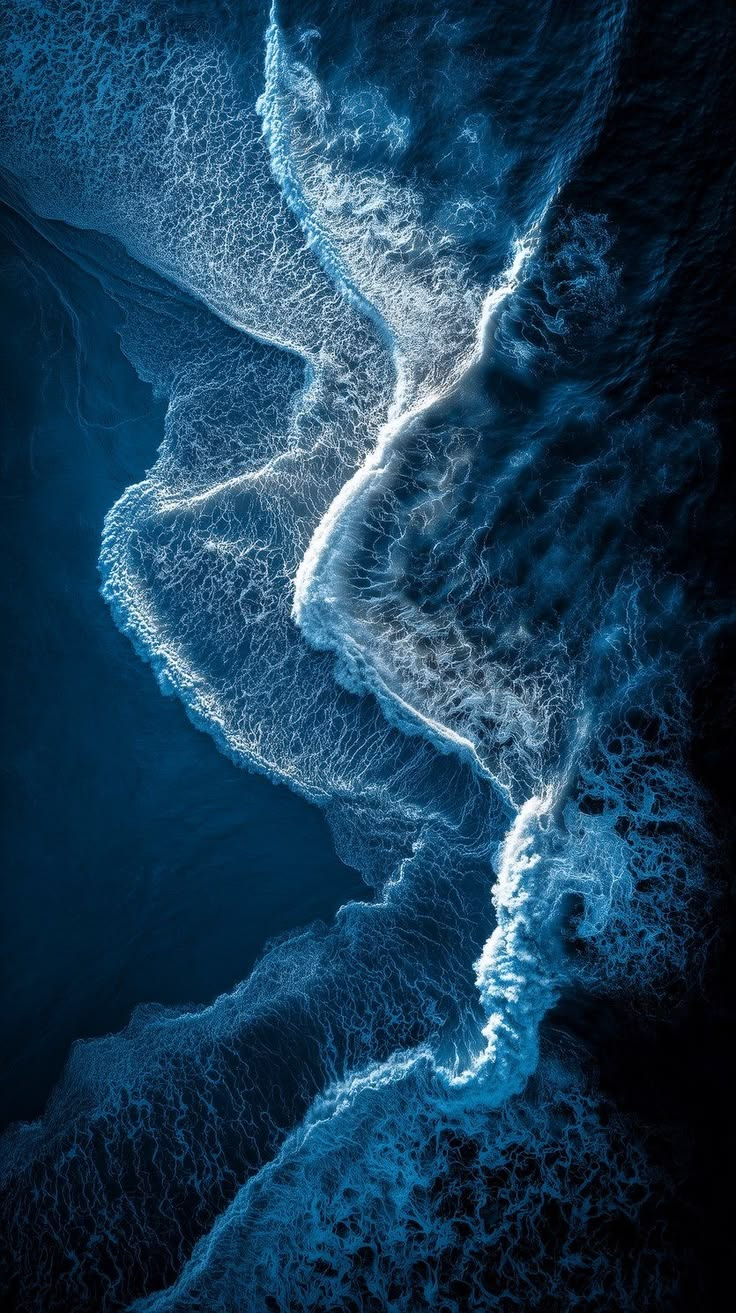

In [12]:
from IPython.display import display, HTML
import base64
import os

# ==========================================
# 1. LOAD SEA BACKGROUND
# ==========================================
image_path = "sea bg.jpg"
if os.path.exists(image_path):
    with open(image_path, "rb") as f:
        bg_base64 = base64.b64encode(f.read()).decode()
else:
    bg_base64 = ""
    print("⚠️ 'sea bg.jpg' not found.")

# ==========================================
# 2. THE GLASS UI
# ==========================================
html_output = f"""
<style>
@import url('https://fonts.googleapis.com/css2?family=Press+Start+2P&display=swap');

/* 1. Full Background Setup */
.jp-OutputArea-output {{
    background-image: url('data:image/jpeg;base64,{bg_base64}') !important;
    background-size: cover !important;
    background-position: center !important;
    background-attachment: fixed !important;
    padding: 50px !important;
    border-radius: 15px !important;
    min-height: 600px;
    display: flex;
    align-items: center;
    justify-content: center;
}}

/* 2. The Frosted Glass Container */
.human-card {{
    background: rgba(15, 23, 42, 0.55) !important; /* Lower opacity to see the sea better */
    backdrop-filter: blur(20px) !important; /* Heavy blur for frosted glass */
    -webkit-backdrop-filter: blur(20px) !important;
    border: 2px solid rgba(255, 255, 255, 0.2) !important;
    border-top: 4px solid #f43f5e !important; /* Red warning top border */
    border-radius: 20px !important;
    padding: 50px !important;
    box-shadow: 0 20px 50px rgba(0, 0, 0, 0.7) !important;
    max-width: 850px;
    text-align: center;
    position: relative;
}}

/* 3. Title */
.human-title {{
    font-family: 'Press Start 2P', cursive;
    font-size: 2rem;
    color: #f43f5e; /* Red */
    margin-bottom: 30px;
    text-shadow: 3px 3px 0px #000, 0 0 20px rgba(244, 63, 94, 0.8);
}}

/* 4. The Fact Text */
.human-fact {{
    font-family: 'Press Start 2P', cursive;
    font-size: 0.8rem;
    color: #ffffff;
    line-height: 2.4;
    text-align: left;
    text-shadow: 2px 2px 0px #000;
}}

.highlight-yellow {{
    color: #f59e0b;
    font-weight: bold;
    font-size: 0.9rem;
}}

.highlight-cyan {{
    color: #38bdf8;
    font-weight: bold;
}}
</style>

<div class="human-card">
    <div class="human-title">THE HUMAN LINK</div>
    <div class="human-fact">
        > <span class="highlight-yellow">THE FACT:</span> Every second breath you take comes from the ocean. Marine phytoplankton produce over 50% of the world's oxygen. 
        <br><br>
        > <span class="highlight-cyan">THE REALITY:</span> When the ocean overheats (as seen in the 2010 SST spike), phytoplankton die or migrate. This isn't just a loss of fish; it is a direct threat to the air we breathe. 
        <br><br>
        > <span class="highlight-yellow">THE PUBLIC HEALTH CRISIS:</span> Warming waters breed toxic algal blooms that contaminate seafood, causing neurological diseases in humans. The mercury accumulating in the sharks we consume leads to severe developmental delays in unborn children.
        <br><br>
        > <span class="highlight-cyan">THE CONCLUSION:</span> We are not separate from the ocean. When the ocean's temperature rises, our oxygen supply drops, our food becomes toxic, and our communities drown. Saving the ocean isn't an environmental act; it is a survival imperative.
    </div>
</div>
"""

display(HTML(html_output))


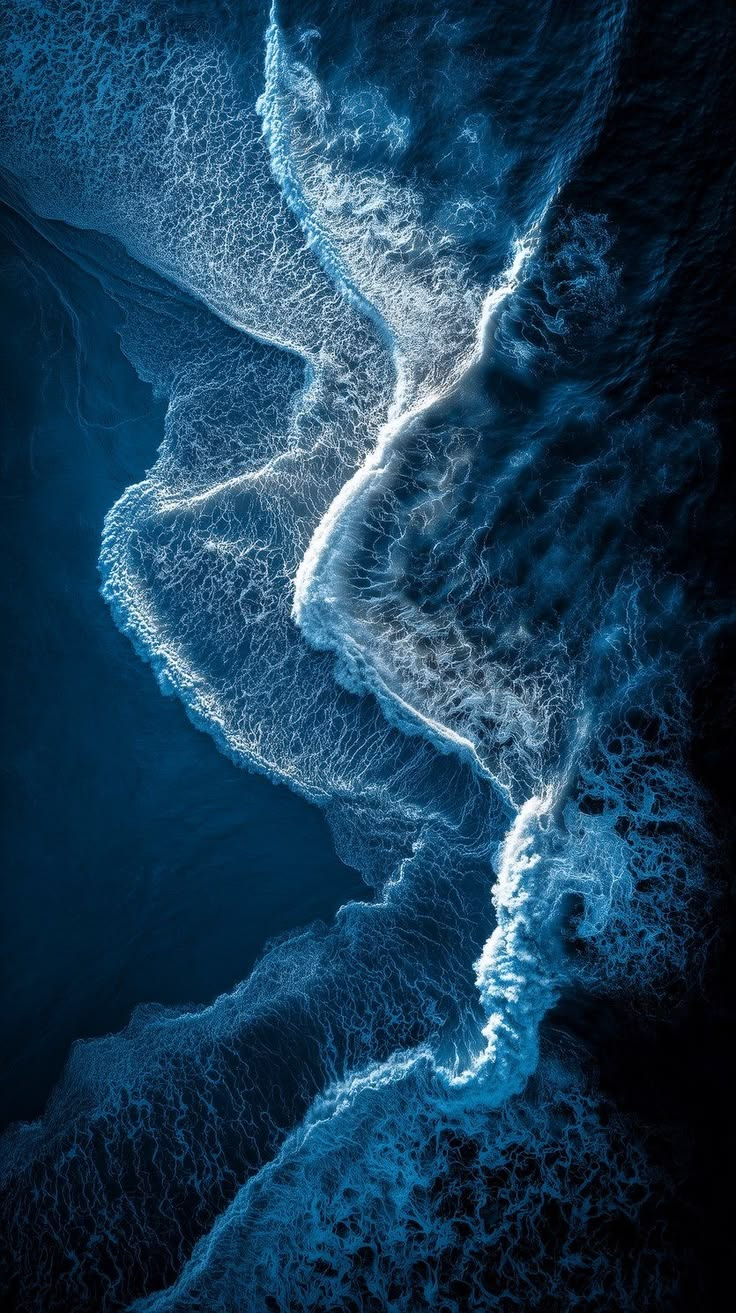

In [13]:
import base64
import os
from IPython.display import display, HTML

# Load Background
image_path = "sea bg.jpg"
bg_base64 = ""
if os.path.exists(image_path):
    with open(image_path, "rb") as f:
        bg_base64 = base64.b64encode(f.read()).decode()

game_over_html = f"""
<div style="background-image: url('data:image/jpeg;base64,{bg_base64}'); background-size: cover; background-position: center; padding: 60px 20px; border-radius: 20px; font-family: 'Press Start 2P', cursive; text-align: center; box-shadow: inset 0 0 100px rgba(0,0,0,0.9); margin-top: 50px;">
    <div style="background: rgba(15, 23, 42, 0.9); border: 4px solid #f59e0b; border-radius: 15px; padding: 40px; display: inline-block; box-shadow: 0 0 30px rgba(245, 158, 11, 0.5);">
        
        <!-- Winning Text -->
        <div style="font-size: 2.5rem; color: #38bdf8; text-shadow: 3px 3px 0px #000, 0 0 20px rgba(56, 189, 248, 0.8); margin-bottom: 20px;">
            PLAYER WON!
        </div>
        
        <!-- Coin Text -->
        <div style="font-size: 3rem; color: #f59e0b; text-shadow: 4px 4px 0px #000, 0 0 20px rgba(245, 158, 11, 0.8); margin-bottom: 20px; animation: pulse 1.5s infinite;">
            +500 COINS 🪙
        </div>
        
        <!-- Subtitle -->
        <div style="font-size: 1rem; color: #10b981; text-shadow: 2px 2px 0px #000;">
            THANKS FOR PLAYING!
        </div>
        
    </div>
</div>

<style>
@keyframes pulse {{
    0% {{ transform: scale(1); }}
    50% {{ transform: scale(1.05); }}
    100% {{ transform: scale(1); }}
}}
</style>
"""

display(HTML(game_over_html))



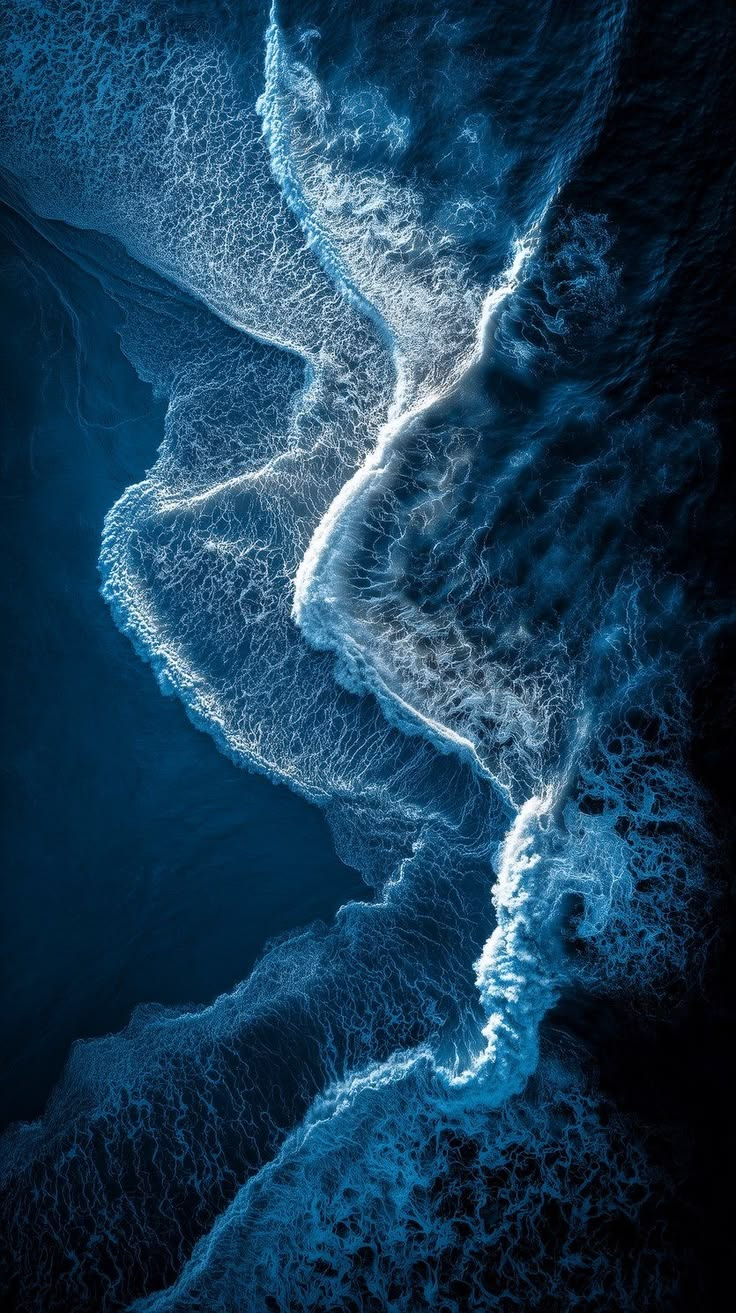

In [14]:
from IPython.display import display, HTML
import base64
import os

# Load Background
image_path = "sea bg.jpg"
bg_base64 = ""
if os.path.exists(image_path):
    with open(image_path, "rb") as f:
        bg_base64 = base64.b64encode(f.read()).decode()

summary_html = f"""
<div style="background-image: url('data:image/jpeg;base64,{bg_base64}'); background-size: cover; background-position: center; padding: 40px; border-radius: 20px; font-family: 'Press Start 2P', cursive; margin-top: 50px; text-align: center;">
    <div style="background: rgba(15, 23, 42, 0.9); border: 3px solid #38bdf8; border-radius: 15px; padding: 30px; display: inline-block; box-shadow: 0 0 30px rgba(56, 189, 248, 0.5); max-width: 800px;">
        
        <h2 style="color: #38bdf8; font-size: 1.5rem; text-shadow: 3px 3px 0px #000; margin-bottom: 30px;">
            GAME SUMMARY
        </h2>
        
        <div style="text-align: left; color: white; font-size: 0.8rem; line-height: 2;">
            <p style="margin-bottom: 15px;">> Data from 2007-2012 shows a fluctuating trend in marine catch across the Indian Coast.</p>
            <p style="margin-bottom: 15px;">> The West Coast (Gujarat & Maharashtra) consistently dominates in total catch volume.</p>
            <p style="margin-bottom: 15px;">> Rising SST anomalies strongly correlate with shifts in fish migration patterns.</p>
            <p>> Thank you for exploring the data! Your analytics journey is complete.</p>
        </div>

    </div>
</div>
"""

display(HTML(summary_html))